In [196]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.spatial.distance import cdist
np.random.seed(10)

In [197]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input
    
class liniowa():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = x
        return self.out

    def backward(self, grad_output):
        return grad_output
    
class tanh():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # f'(x) = 1 - f(x)^2
        return grad_output * (1 - self.out ** 2)

In [198]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [199]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [200]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [201]:
def mse(y_true, y_pred):
    if y_true.ndim == 1 and y_pred.ndim == 2:
        liczba_klas = y_pred.shape[1]
        y_true_onehot = np.zeros_like(y_pred)
        y_true_onehot[np.arange(len(y_true)), y_true] = 1
        y_true_do_obliczen = y_true_onehot
    else:
        y_true_do_obliczen = y_true
        
    return np.mean((y_true_do_obliczen - y_pred) ** 2)

In [202]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [203]:
def wykres_dopasowania_klasyfikacja(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

In [204]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_f1, hist_wagi, epoki, regresja=True, test=False):
    if (test):
        if regresja:
            # Wykres MSE
            plt.figure(figsize=(10, 4))
            plt.plot(range(epoki), hist_f1, color='red')
            plt.title('Wzrost MSE w kolejnych epokach')
            plt.xlabel('Epoka')
            plt.ylabel('MSE')
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.show()
        else:
            # Wykres F1
            plt.figure(figsize=(10, 4))
            plt.plot(range(epoki), hist_f1, color='red')
            plt.title('Wzrost F1 w kolejnych epokach')
            plt.xlabel('Epoka')
            plt.ylabel('F1-score')
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.show()

    if regresja:
        # Wykresy dopasowania regresja
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # Zbiór Treningowy
        ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax1.set_title('Dopasowanie - Zbiór Treningowy')
        ax1.legend()

        # Zbiór Testowy
        ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax2.set_title('Dopasowanie - Zbiór Testowy')
        ax2.legend()
        
    else:
        # Wykresy dopasowania klasyfikacja
        y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
        y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
        
        y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
        y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        wykres_dopasowania_klasyfikacja(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')
        wykres_dopasowania_klasyfikacja(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')

    plt.tight_layout()
    plt.show()

In [205]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, funkcja_straty=MSE, regresja=True, test=False, test_score=False):
    # Skalowanie cech X
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)

    # Skalowanie Y tylko jeśli to regresja
    if regresja:
        y_min = y_train.min(axis=0)
        y_max = y_train.max(axis=0)
        y_train_scaled = (y_train - y_min) / (y_max - y_min)
    else:
        y_train_scaled = y_train
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_score = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście w przód dla batcha
            y_pred_batch = model.forward(X_batch)
            
            # Strata i gradient
            loss = strata.forward(y_pred_batch, y_batch)
            grad_output = strata.backward() 
            
            # Wsteczna propagacja
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Wyliczenie wyników co epokę
        y_pred_all = model.forward(X_train_scaled)

        if regresja:        
            y_pred_all_do_oceny = y_pred_all * (y_max - y_min) + y_min
            score_treningowe = mse(y_train, y_pred_all_do_oceny)
            nazwa_score = "MSE"
        else:
            y_pred_all_do_oceny = y_pred_all
            score_treningowe = f1(y_train, y_pred_all_do_oceny)
            nazwa_score = "F1"

        hist_score.append(score_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_score:
                y_pred_test = model.forward(X_test_scaled)
                if regresja:
                    y_pred_test_unscaled = y_pred_test * (y_max - y_min) + y_min
                    score_testowe_krok = mse(y_test, y_pred_test_unscaled)
                else:
                    score_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | {nazwa_score} Test: {score_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f}")

    print("-" * 50)
    print(f"{nazwa_score} treningowe FINALNE: {hist_score[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    if regresja:
        y_pred_test_final_do_oceny = y_pred_test_final * (y_max - y_min) + y_min
        score_test = mse(y_test, y_pred_test_final_do_oceny)
    else:
        y_pred_test_final_do_oceny = y_pred_test_final
        score_test = f1(y_test, y_pred_test_final_do_oceny)
        
    print(f"{nazwa_score} testowe FINALNE: {score_test:.4f}")

    # Rysowanie wykresów
    wykresy(X_train, y_train, X_test, y_test, y_pred_all_do_oceny, y_pred_test_final_do_oceny, hist_score, hist_wagi, epoki, regresja, test)

    return hist_score, score_test

In [206]:
def wykres_score(zbior, score, hist_sigmoid=None, hist_line=None, hist_relu=None, hist_tanh=None, warstwa=1):
    plt.figure(figsize=(10, 5))

    if hist_sigmoid is not None:
        plt.plot(hist_sigmoid, label='Sigmoid', color='#ff6b6b', linewidth=2)
        
    if hist_line is not None:
        plt.plot(hist_line, label='Liniowa', color='#4ecdc4', linewidth=2)
        
    if hist_relu is not None:
        plt.plot(hist_relu, label='ReLU', color="#17bd61", linewidth=2)
        
    if hist_tanh is not None:
        plt.plot(hist_tanh, label='Tanh', color="#faee04", linewidth=2)

    plt.title(f'Porównanie zbieżności różnych funkcji aktywacji ({zbior}) - {warstwa} warstwa(y)', fontsize=14)
    plt.xlabel('Epoka', fontsize=12)
    
    plt.ylabel(score, fontsize=12) 

    plt.legend(fontsize=12, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [207]:
def wykres_warstwy_funkcja(ax, hist_1, hist_2, hist_3, score, funkcja):
    if hist_1 is not None:
        ax.plot(hist_1, label='1 warstwa ukryta', color='#ff6b6b', linewidth=2)
    if hist_2 is not None:
        ax.plot(hist_2, label='2 warstwy ukryte', color='#4ecdc4', linewidth=2)
    if hist_3 is not None:
        ax.plot(hist_3, label='3 warstwy ukryte', color="#17bd61", linewidth=2)

    ax.set_title(f'Funkcja {funkcja}', fontsize=14)
    ax.set_xlabel('Epoka', fontsize=12)
    ax.set_ylabel(score, fontsize=12)

    ax.legend(fontsize=11, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)

In [208]:
def wykresy_warstwy(dane_historii, zbior, score):
    dostepne_funkcje = [f for f in ['Sigmoid', 'Liniowa', 'ReLU', 'Tanh'] if f in dane_historii]
    liczba_wykresow = len(dostepne_funkcje)
    
    if liczba_wykresow == 0:
        print("Brak danych do narysowania.")
        return

    if liczba_wykresow == 1:
        fig, axes = plt.subplots(1, 1, figsize=(8, 5))
        axes = [axes]
    elif liczba_wykresow == 2:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    else:
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        axes = axes.flatten()

    fig.suptitle(f'Porównanie zbieżności architektur dla różnych aktywacji ({zbior})', fontsize=16, fontweight='bold')

    for i, funkcja in enumerate(dostepne_funkcje):
        hist_1, hist_2, hist_3 = dane_historii[funkcja]
        wykres_warstwy_funkcja(axes[i], hist_1, hist_2, hist_3, score, funkcja)

    if liczba_wykresow > 1:
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

    plt.tight_layout()
    plt.subplots_adjust(top=0.92 if liczba_wykresow > 2 else 0.85) 
    plt.show()

In [209]:
def porownanie_scatter(dane_wynikow, zbior="Zbiór Testowy"):
    plt.figure(figsize=(12, 8))
    
    kolory_funkcji = {
        'Sigmoid': '#ff6b6b',
        'Liniowa': '#4ecdc4',
        'ReLU': '#17bd61',
        'Tanh': '#faee04'
    }
    
    markery_warstw = {
        1: 'o',
        2: 's',
        3: '^'
    }
    
    neurony_x = [5, 10, 20]
    
    for funkcja, kolor in kolory_funkcji.items():
        if funkcja not in dane_wynikow:
            continue
            
        for warstwy, marker in markery_warstw.items():
            if warstwy not in dane_wynikow[funkcja]:
                continue
                
            dane_warstwy = dane_wynikow[funkcja][warstwy]
            
            valid_x = []
            valid_y = []
            for n in neurony_x:
                if n in dane_warstwy and dane_warstwy[n] is not None:
                    valid_x.append(n)
                    valid_y.append(dane_warstwy[n])
            
            if valid_x:
                plt.scatter(valid_x, valid_y, 
                            color=kolor, marker=marker, 
                            s=150, edgecolor='black', alpha=0.8, zorder=3)

    legenda_funkcji = [Line2D([0], [0], marker='o', color='w', 
                              markerfacecolor=k, markersize=12, label=f) 
                       for f, k in kolory_funkcji.items()]
                      
    legenda_warstw = [Line2D([0], [0], marker=m, color='w', 
                             markeredgecolor='black', markerfacecolor='gray', 
                             markersize=12, label=f'{w} warstwa(y)') 
                      for w, m in markery_warstw.items()]
                       
    leg1 = plt.legend(handles=legenda_funkcji, title="Aktywacja (Kolor)", 
                      loc='upper left', bbox_to_anchor=(1.02, 1), 
                      fontsize=11, title_fontsize=12)
    
    plt.gca().add_artist(leg1) 
    
    plt.legend(handles=legenda_warstw, title="Liczba warstw (Kształt)", 
               loc='upper left', bbox_to_anchor=(1.02, 0.72), 
               fontsize=11, title_fontsize=12)

    plt.title(f'Zestawienie MSE dla architektur sieci ({zbior})', fontsize=16, fontweight='bold')
    plt.xlabel('Liczba neuronów w warstwach ukrytych', fontsize=12)
    plt.ylabel('Finalne MSE Testowe', fontsize=12)
    
    plt.xticks(neurony_x)
    plt.grid(True, linestyle='--', alpha=0.5, zorder=0)
    
    plt.tight_layout()
    plt.subplots_adjust(right=0.75) 
    plt.show()

In [210]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane multimodal-large

In [211]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")
X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

## Jedna warstwa ukryta

Krok     0 | MSE Trening: 4598.2681
Krok   100 | MSE Trening: 2568.7316
Krok   200 | MSE Trening: 2433.2655
Krok   300 | MSE Trening: 2287.1260
Krok   400 | MSE Trening: 1677.9136
Krok   500 | MSE Trening: 681.2560
Krok   600 | MSE Trening: 616.2432
Krok   700 | MSE Trening: 583.8950
Krok   800 | MSE Trening: 569.5754
Krok   900 | MSE Trening: 553.3461
Krok  1000 | MSE Trening: 598.1952
Krok  1100 | MSE Trening: 538.4588
Krok  1200 | MSE Trening: 550.8526
Krok  1300 | MSE Trening: 557.0883
Krok  1400 | MSE Trening: 578.2454
Krok  1500 | MSE Trening: 568.7147
Krok  1600 | MSE Trening: 457.5754
Krok  1700 | MSE Trening: 438.6847
Krok  1800 | MSE Trening: 427.8709
Krok  1900 | MSE Trening: 457.7047
--------------------------------------------------
MSE treningowe FINALNE: 431.0555
MSE testowe FINALNE: 432.1063


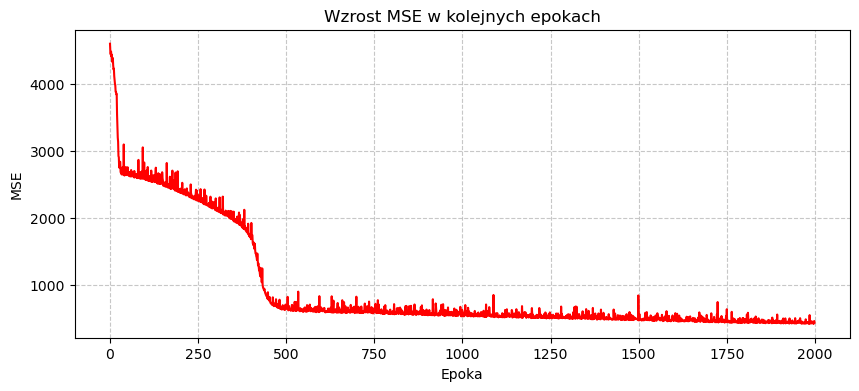

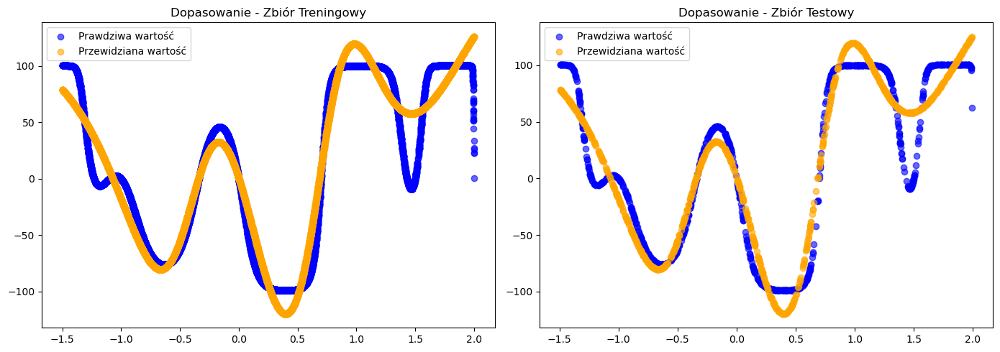

In [212]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_1_5, sigmoid_1_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4628.0522
Krok   100 | MSE Trening: 2587.1664
Krok   200 | MSE Trening: 2499.2651
Krok   300 | MSE Trening: 2260.0428
Krok   400 | MSE Trening: 1946.9343
Krok   500 | MSE Trening: 818.5900
Krok   600 | MSE Trening: 596.6530
Krok   700 | MSE Trening: 594.1505
Krok   800 | MSE Trening: 561.5638
Krok   900 | MSE Trening: 542.1677
Krok  1000 | MSE Trening: 586.5723
Krok  1100 | MSE Trening: 524.3437
Krok  1200 | MSE Trening: 507.5305
Krok  1300 | MSE Trening: 502.4028
Krok  1400 | MSE Trening: 481.9562
Krok  1500 | MSE Trening: 477.1394
Krok  1600 | MSE Trening: 460.9002
Krok  1700 | MSE Trening: 455.8017
Krok  1800 | MSE Trening: 541.0088
Krok  1900 | MSE Trening: 469.4514
--------------------------------------------------
MSE treningowe FINALNE: 453.4189
MSE testowe FINALNE: 446.5236


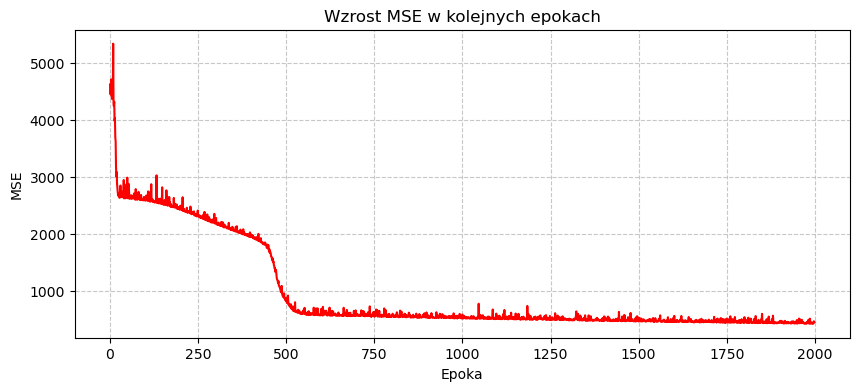

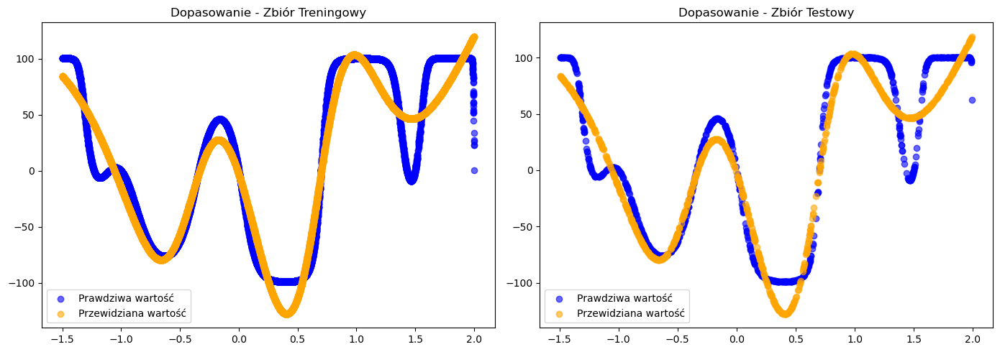

In [213]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_1_10, sigmoid_1_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4431.3482
Krok   100 | MSE Trening: 2591.3013
Krok   200 | MSE Trening: 2469.3264
Krok   300 | MSE Trening: 2253.3653
Krok   400 | MSE Trening: 2188.8824
Krok   500 | MSE Trening: 1925.1452
Krok   600 | MSE Trening: 1223.2765
Krok   700 | MSE Trening: 615.7768
Krok   800 | MSE Trening: 644.9900
Krok   900 | MSE Trening: 600.0434
Krok  1000 | MSE Trening: 622.9331
Krok  1100 | MSE Trening: 583.0717
Krok  1200 | MSE Trening: 620.6974
Krok  1300 | MSE Trening: 576.9755
Krok  1400 | MSE Trening: 572.5104
Krok  1500 | MSE Trening: 564.4808
Krok  1600 | MSE Trening: 585.4183
Krok  1700 | MSE Trening: 581.2151
Krok  1800 | MSE Trening: 679.2403
Krok  1900 | MSE Trening: 523.6175
--------------------------------------------------
MSE treningowe FINALNE: 515.8329
MSE testowe FINALNE: 525.6514


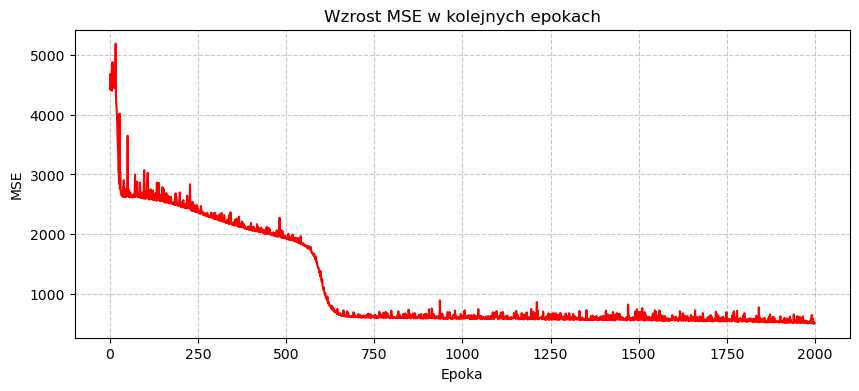

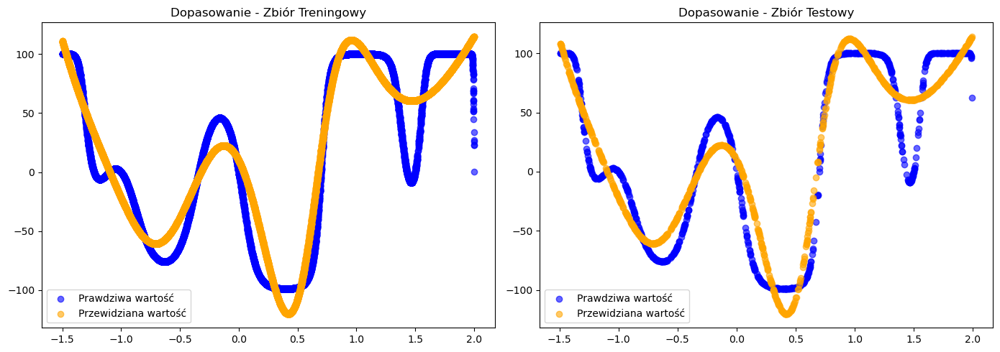

In [214]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_1_20, sigmoid_1_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4497.6616
Krok   100 | MSE Trening: 4436.2690
Krok   200 | MSE Trening: 4423.3447
Krok   300 | MSE Trening: 4527.7677
Krok   400 | MSE Trening: 4507.7568
Krok   500 | MSE Trening: 4409.2157
Krok   600 | MSE Trening: 4586.9099
Krok   700 | MSE Trening: 4401.2934
Krok   800 | MSE Trening: 4402.8868
Krok   900 | MSE Trening: 4408.1407
Krok  1000 | MSE Trening: 4447.0132
Krok  1100 | MSE Trening: 4423.2534
Krok  1200 | MSE Trening: 4426.3613
Krok  1300 | MSE Trening: 4415.8112
Krok  1400 | MSE Trening: 4409.9462
Krok  1500 | MSE Trening: 4599.7845
Krok  1600 | MSE Trening: 4428.0780
Krok  1700 | MSE Trening: 4406.8021
Krok  1800 | MSE Trening: 4409.3788
Krok  1900 | MSE Trening: 4409.8728
--------------------------------------------------
MSE treningowe FINALNE: 4430.8074
MSE testowe FINALNE: 4466.8952


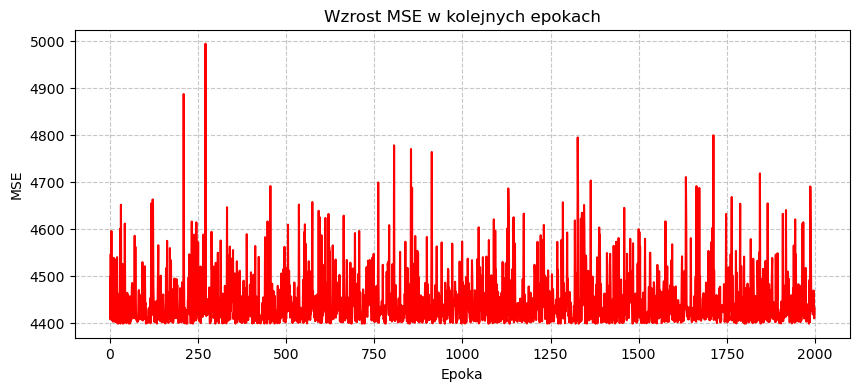

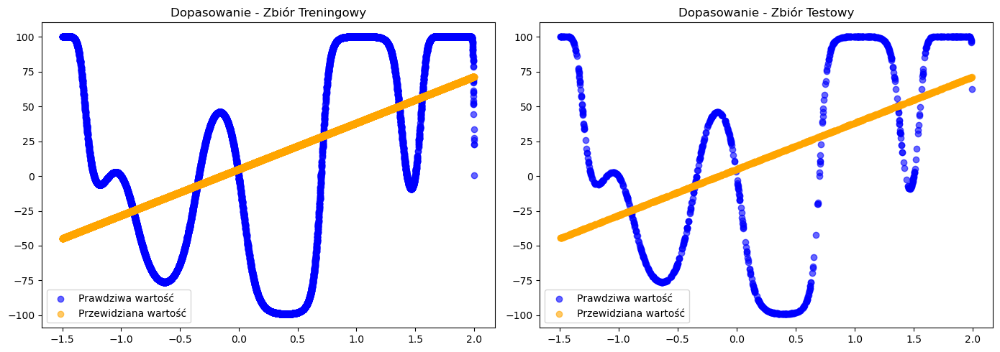

In [215]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_1_5, liniowa_1_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4478.9553
Krok   100 | MSE Trening: 4452.9418
Krok   200 | MSE Trening: 4447.9152
Krok   300 | MSE Trening: 4405.3402
Krok   400 | MSE Trening: 4473.1840
Krok   500 | MSE Trening: 4431.7196
Krok   600 | MSE Trening: 4405.9122
Krok   700 | MSE Trening: 4509.1825
Krok   800 | MSE Trening: 4400.7274
Krok   900 | MSE Trening: 4398.4877
Krok  1000 | MSE Trening: 4629.9868
Krok  1100 | MSE Trening: 4415.5422
Krok  1200 | MSE Trening: 4529.4922
Krok  1300 | MSE Trening: 4413.8260
Krok  1400 | MSE Trening: 4411.9746
Krok  1500 | MSE Trening: 4467.1274
Krok  1600 | MSE Trening: 4428.5754
Krok  1700 | MSE Trening: 4410.8146
Krok  1800 | MSE Trening: 4399.3803
Krok  1900 | MSE Trening: 4405.1782
--------------------------------------------------
MSE treningowe FINALNE: 4592.9139
MSE testowe FINALNE: 4638.6211


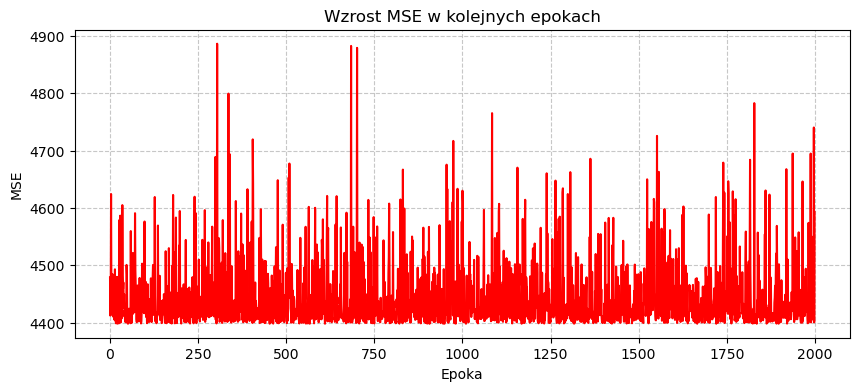

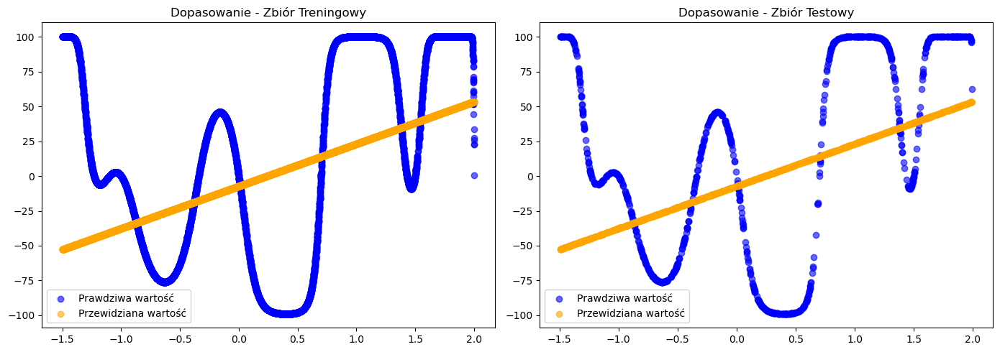

In [216]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_1_10, liniowa_1_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4441.9759
Krok   100 | MSE Trening: 4479.7411
Krok   200 | MSE Trening: 4417.1681
Krok   300 | MSE Trening: 4563.3885
Krok   400 | MSE Trening: 4402.2559
Krok   500 | MSE Trening: 4417.4438
Krok   600 | MSE Trening: 4483.6409
Krok   700 | MSE Trening: 4446.8562
Krok   800 | MSE Trening: 4465.8738
Krok   900 | MSE Trening: 4420.8809
Krok  1000 | MSE Trening: 4522.4694
Krok  1100 | MSE Trening: 4540.1062
Krok  1200 | MSE Trening: 4415.4898
Krok  1300 | MSE Trening: 4505.8446
Krok  1400 | MSE Trening: 4409.5993
Krok  1500 | MSE Trening: 4419.6929
Krok  1600 | MSE Trening: 4452.2860
Krok  1700 | MSE Trening: 4411.4968
Krok  1800 | MSE Trening: 4413.4297
Krok  1900 | MSE Trening: 4461.1184
--------------------------------------------------
MSE treningowe FINALNE: 4401.0941
MSE testowe FINALNE: 4435.8506


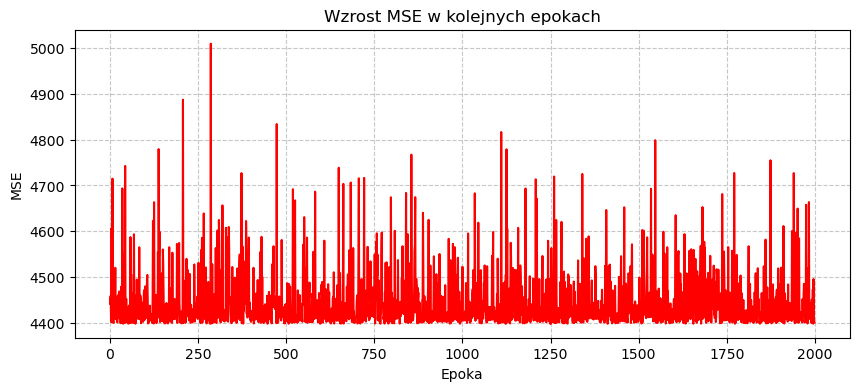

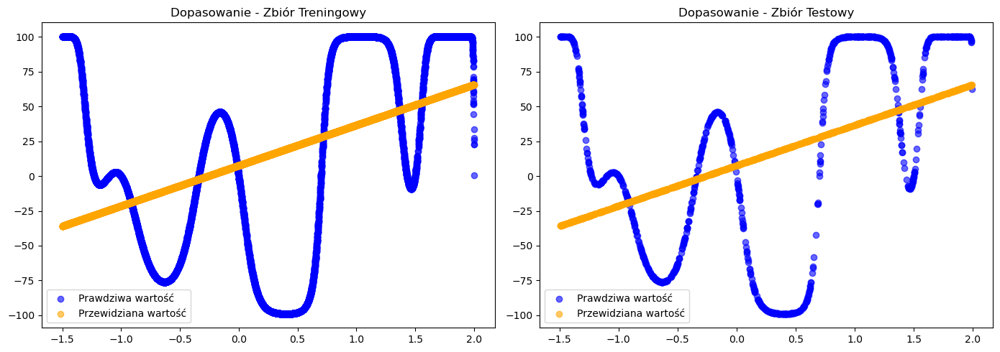

In [217]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_1_20, liniowa_1_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4308.3383
Krok   100 | MSE Trening: 2740.3535
Krok   200 | MSE Trening: 2717.9670
Krok   300 | MSE Trening: 2950.9781
Krok   400 | MSE Trening: 2770.5258
Krok   500 | MSE Trening: 2892.2572
Krok   600 | MSE Trening: 2733.0725
Krok   700 | MSE Trening: 2723.4921
Krok   800 | MSE Trening: 2750.8179
Krok   900 | MSE Trening: 2733.6531
Krok  1000 | MSE Trening: 2723.3304
Krok  1100 | MSE Trening: 2755.8690
Krok  1200 | MSE Trening: 2745.7542
Krok  1300 | MSE Trening: 2723.1162
Krok  1400 | MSE Trening: 2739.1994
Krok  1500 | MSE Trening: 2746.8589
Krok  1600 | MSE Trening: 2717.7211
Krok  1700 | MSE Trening: 2735.3962
Krok  1800 | MSE Trening: 2763.3684
Krok  1900 | MSE Trening: 2772.3990
--------------------------------------------------
MSE treningowe FINALNE: 2732.7253
MSE testowe FINALNE: 2751.7257


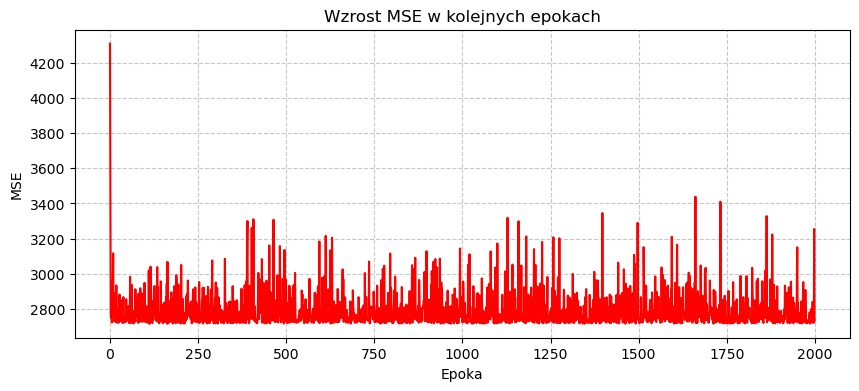

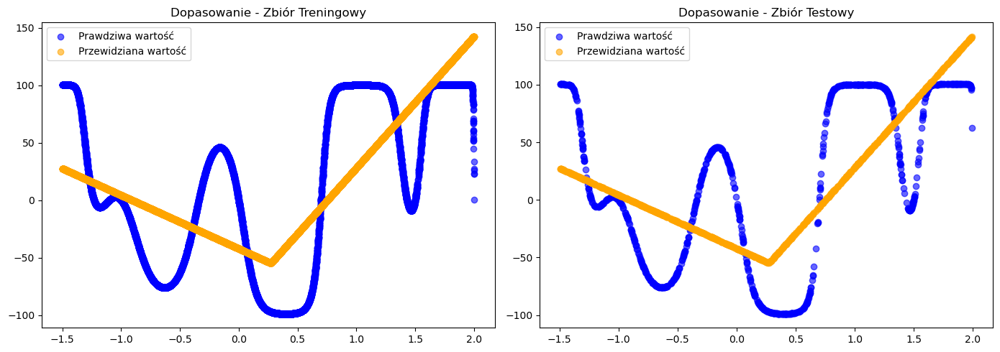

In [218]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_1_5, relu_1_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 3231.6385
Krok   100 | MSE Trening: 3252.0672
Krok   200 | MSE Trening: 3288.5382
Krok   300 | MSE Trening: 3236.9628
Krok   400 | MSE Trening: 3217.1802
Krok   500 | MSE Trening: 3277.7350
Krok   600 | MSE Trening: 3228.2244
Krok   700 | MSE Trening: 3208.4975
Krok   800 | MSE Trening: 3205.6450
Krok   900 | MSE Trening: 3211.1118
Krok  1000 | MSE Trening: 3223.6411
Krok  1100 | MSE Trening: 3313.2847
Krok  1200 | MSE Trening: 3215.6639
Krok  1300 | MSE Trening: 3207.7846
Krok  1400 | MSE Trening: 3222.9526
Krok  1500 | MSE Trening: 3221.3154
Krok  1600 | MSE Trening: 3261.2694
Krok  1700 | MSE Trening: 3371.7951
Krok  1800 | MSE Trening: 3321.1783
Krok  1900 | MSE Trening: 3228.0583
--------------------------------------------------
MSE treningowe FINALNE: 3365.6746
MSE testowe FINALNE: 3422.3169


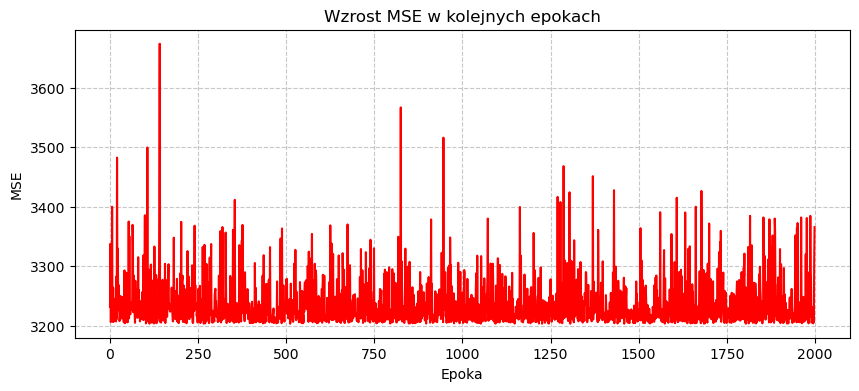

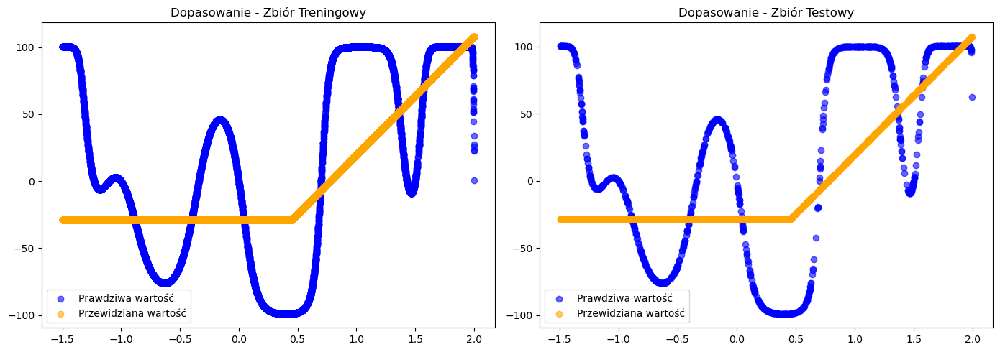

In [219]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_1_10, relu_1_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 3217.6174
Krok   100 | MSE Trening: 3313.4701
Krok   200 | MSE Trening: 3343.5874
Krok   300 | MSE Trening: 3255.4702
Krok   400 | MSE Trening: 3207.4135
Krok   500 | MSE Trening: 3276.1104
Krok   600 | MSE Trening: 3219.5485
Krok   700 | MSE Trening: 3221.6198
Krok   800 | MSE Trening: 3255.7554
Krok   900 | MSE Trening: 3215.4626
Krok  1000 | MSE Trening: 3427.7847
Krok  1100 | MSE Trening: 3205.4992
Krok  1200 | MSE Trening: 3208.4873
Krok  1300 | MSE Trening: 3225.0393
Krok  1400 | MSE Trening: 3313.2427
Krok  1500 | MSE Trening: 3216.6814
Krok  1600 | MSE Trening: 3245.7289
Krok  1700 | MSE Trening: 3257.7791
Krok  1800 | MSE Trening: 3313.3848
Krok  1900 | MSE Trening: 3212.0437
--------------------------------------------------
MSE treningowe FINALNE: 3306.2851
MSE testowe FINALNE: 3366.6259


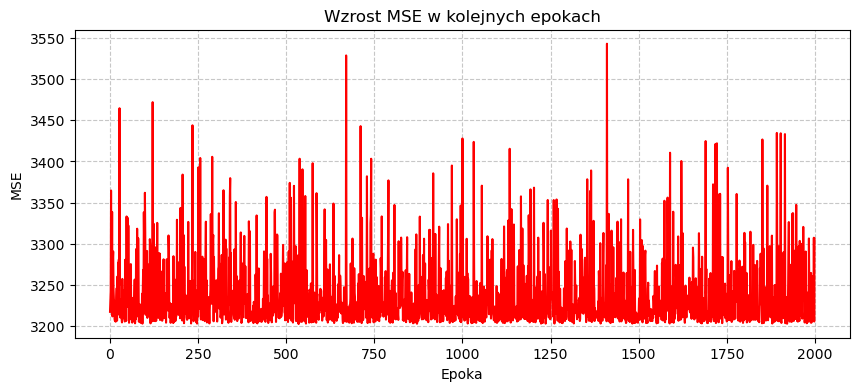

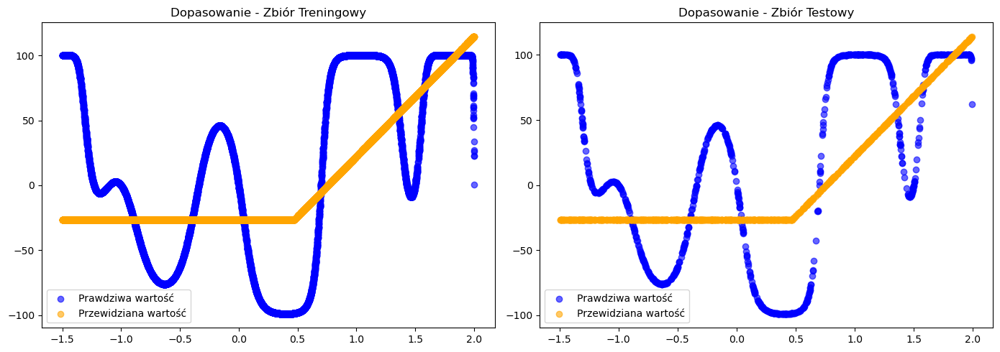

In [220]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_1_20, relu_1_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4456.1560
Krok   100 | MSE Trening: 985.4573
Krok   200 | MSE Trening: 534.5690
Krok   300 | MSE Trening: 497.5208
Krok   400 | MSE Trening: 544.3484
Krok   500 | MSE Trening: 497.3244
Krok   600 | MSE Trening: 443.9895
Krok   700 | MSE Trening: 420.2904
Krok   800 | MSE Trening: 383.2360
Krok   900 | MSE Trening: 387.5757
Krok  1000 | MSE Trening: 442.9933
Krok  1100 | MSE Trening: 373.6079
Krok  1200 | MSE Trening: 346.4180
Krok  1300 | MSE Trening: 461.5186
Krok  1400 | MSE Trening: 327.6178
Krok  1500 | MSE Trening: 338.6711
Krok  1600 | MSE Trening: 345.9679
Krok  1700 | MSE Trening: 305.8250
Krok  1800 | MSE Trening: 308.7038
Krok  1900 | MSE Trening: 341.8981
--------------------------------------------------
MSE treningowe FINALNE: 356.7836
MSE testowe FINALNE: 360.5157


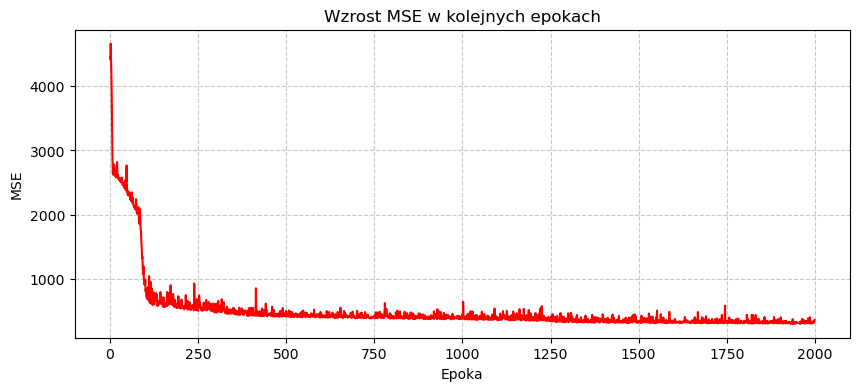

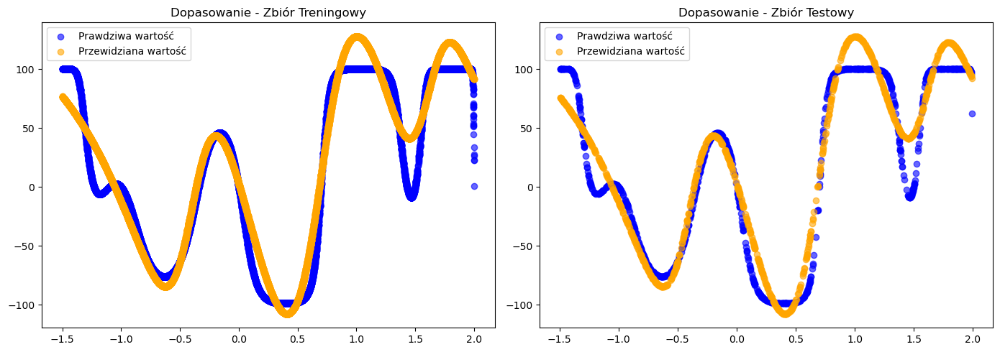

In [221]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_1_5, tanh_1_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4411.2978
Krok   100 | MSE Trening: 1132.4164
Krok   200 | MSE Trening: 638.2522
Krok   300 | MSE Trening: 601.5786
Krok   400 | MSE Trening: 488.5740
Krok   500 | MSE Trening: 402.1182
Krok   600 | MSE Trening: 373.4483
Krok   700 | MSE Trening: 342.4402
Krok   800 | MSE Trening: 377.1111
Krok   900 | MSE Trening: 347.8458
Krok  1000 | MSE Trening: 318.4602
Krok  1100 | MSE Trening: 359.8441
Krok  1200 | MSE Trening: 307.9045
Krok  1300 | MSE Trening: 309.8368
Krok  1400 | MSE Trening: 290.8140
Krok  1500 | MSE Trening: 312.3145
Krok  1600 | MSE Trening: 286.7999
Krok  1700 | MSE Trening: 304.6549
Krok  1800 | MSE Trening: 251.3998
Krok  1900 | MSE Trening: 273.1530
--------------------------------------------------
MSE treningowe FINALNE: 219.9690
MSE testowe FINALNE: 232.4052


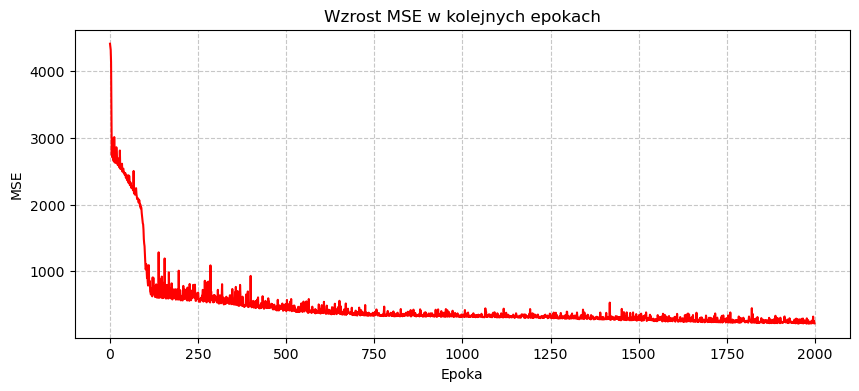

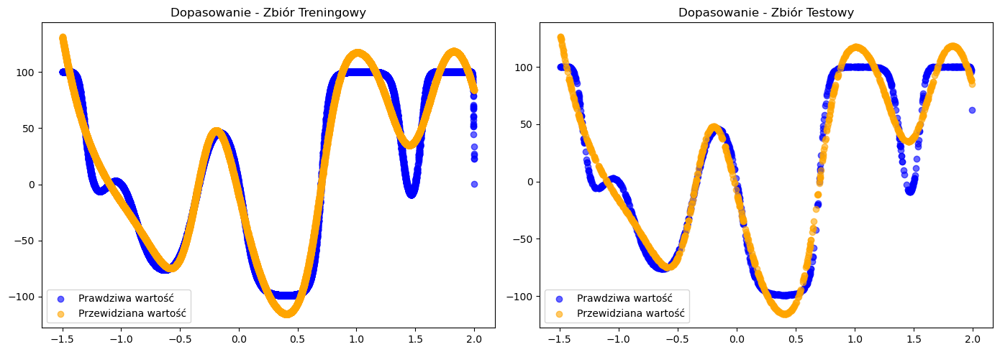

In [222]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_1_10, tanh_1_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4422.4277
Krok   100 | MSE Trening: 2107.2527
Krok   200 | MSE Trening: 1821.2813
Krok   300 | MSE Trening: 697.0675
Krok   400 | MSE Trening: 633.5159
Krok   500 | MSE Trening: 590.1910
Krok   600 | MSE Trening: 586.4639
Krok   700 | MSE Trening: 409.4759
Krok   800 | MSE Trening: 358.7855
Krok   900 | MSE Trening: 328.9301
Krok  1000 | MSE Trening: 321.2234
Krok  1100 | MSE Trening: 355.9447
Krok  1200 | MSE Trening: 413.4170
Krok  1300 | MSE Trening: 339.8304
Krok  1400 | MSE Trening: 410.8689
Krok  1500 | MSE Trening: 350.5822
Krok  1600 | MSE Trening: 359.8352
Krok  1700 | MSE Trening: 325.5252
Krok  1800 | MSE Trening: 315.7356
Krok  1900 | MSE Trening: 311.8326
--------------------------------------------------
MSE treningowe FINALNE: 291.0993
MSE testowe FINALNE: 299.6672


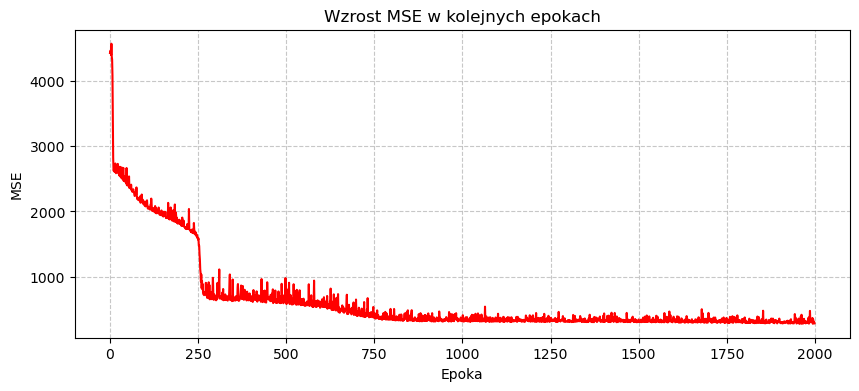

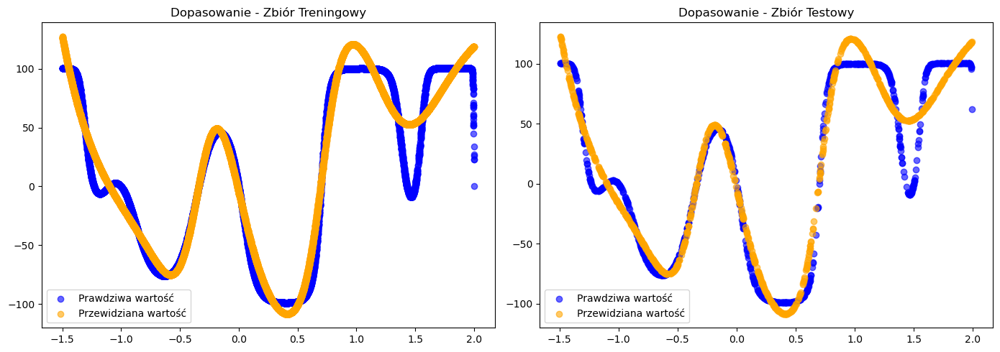

In [223]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_1_20, tanh_1_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

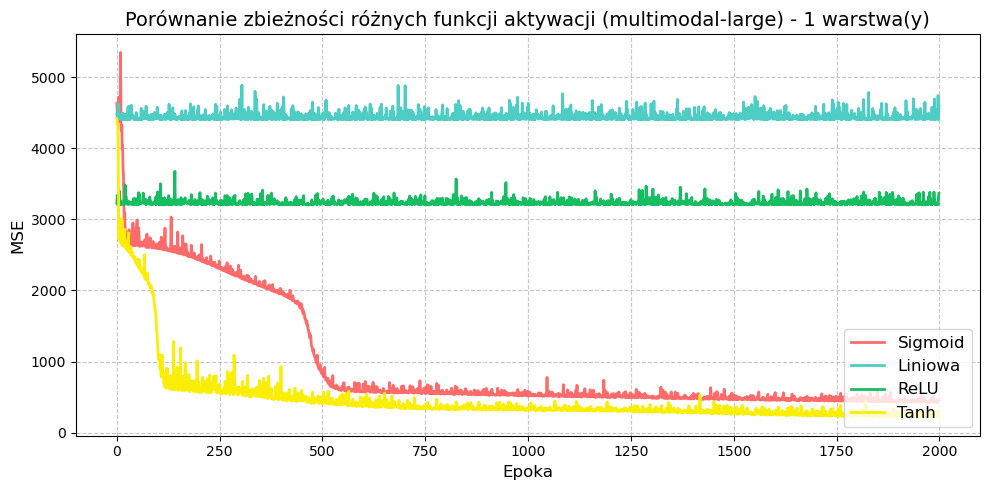

In [224]:
wykres_score('multimodal-large', 'MSE', hist_sigmoid_1_10, hist_liniowa_1_10, hist_relu_1_10, hist_tanh_1_10, 1)

## Dwie warstwy ukryte

Krok     0 | MSE Trening: 5157.0406
Krok   100 | MSE Trening: 1753.2456
Krok   200 | MSE Trening: 653.7485
Krok   300 | MSE Trening: 674.3615
Krok   400 | MSE Trening: 641.8364
Krok   500 | MSE Trening: 509.7624
Krok   600 | MSE Trening: 468.2216
Krok   700 | MSE Trening: 429.9236
Krok   800 | MSE Trening: 509.9948
Krok   900 | MSE Trening: 385.8254
Krok  1000 | MSE Trening: 393.7527
Krok  1100 | MSE Trening: 355.5683
Krok  1200 | MSE Trening: 341.0674
Krok  1300 | MSE Trening: 317.8065
Krok  1400 | MSE Trening: 302.3079
Krok  1500 | MSE Trening: 310.5448
Krok  1600 | MSE Trening: 293.4257
Krok  1700 | MSE Trening: 287.2804
Krok  1800 | MSE Trening: 339.8250
Krok  1900 | MSE Trening: 267.9702
--------------------------------------------------
MSE treningowe FINALNE: 271.5745
MSE testowe FINALNE: 287.8356


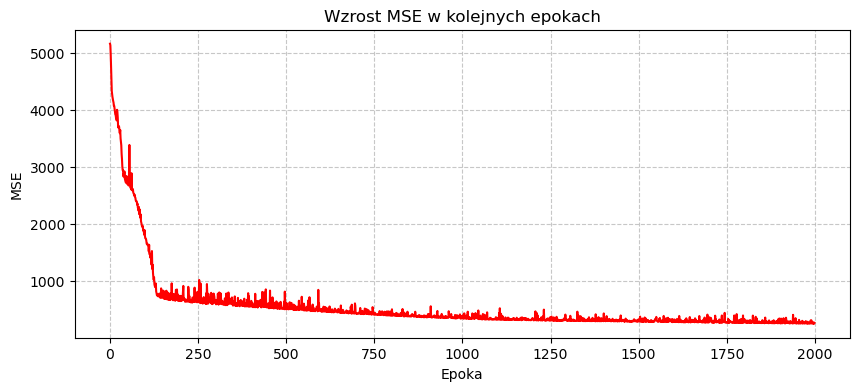

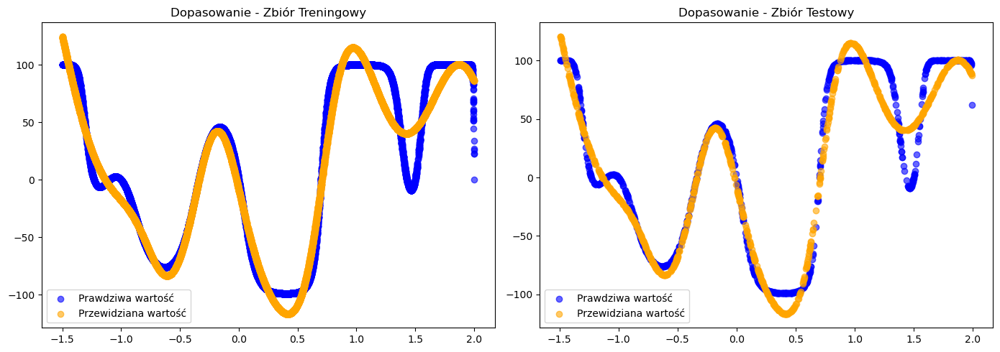

In [225]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2_5, sigmoid_2_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4820.4592
Krok   100 | MSE Trening: 1899.4624
Krok   200 | MSE Trening: 382.4477
Krok   300 | MSE Trening: 357.9052
Krok   400 | MSE Trening: 359.1627
Krok   500 | MSE Trening: 302.3364
Krok   600 | MSE Trening: 314.7962
Krok   700 | MSE Trening: 255.3837
Krok   800 | MSE Trening: 191.1490
Krok   900 | MSE Trening: 173.0231
Krok  1000 | MSE Trening: 134.1499
Krok  1100 | MSE Trening: 122.0408
Krok  1200 | MSE Trening: 109.3597
Krok  1300 | MSE Trening: 101.5195
Krok  1400 | MSE Trening: 102.2504
Krok  1500 | MSE Trening: 100.1840
Krok  1600 | MSE Trening:  90.6847
Krok  1700 | MSE Trening:  86.8172
Krok  1800 | MSE Trening:  85.0448
Krok  1900 | MSE Trening:  82.7671
--------------------------------------------------
MSE treningowe FINALNE: 78.9528
MSE testowe FINALNE: 70.7763


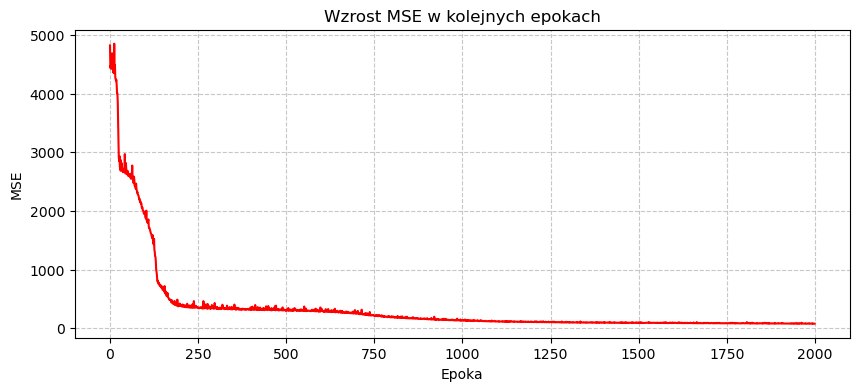

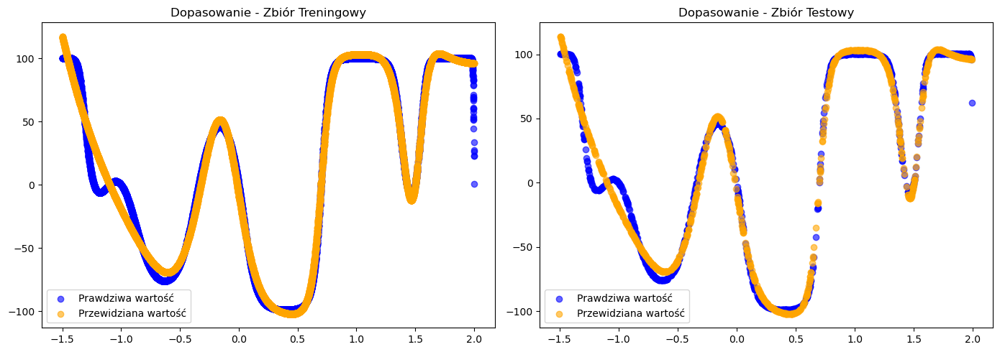

In [226]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2_10, sigmoid_2_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 5142.9259
Krok   100 | MSE Trening: 1797.4042
Krok   200 | MSE Trening: 637.1756
Krok   300 | MSE Trening: 402.4314
Krok   400 | MSE Trening: 359.6331
Krok   500 | MSE Trening: 296.5288
Krok   600 | MSE Trening: 235.5978
Krok   700 | MSE Trening: 215.3429
Krok   800 | MSE Trening: 193.6621
Krok   900 | MSE Trening: 168.4384
Krok  1000 | MSE Trening: 137.7788
Krok  1100 | MSE Trening: 113.4481
Krok  1200 | MSE Trening: 107.9884
Krok  1300 | MSE Trening: 101.7893
Krok  1400 | MSE Trening:  95.0758
Krok  1500 | MSE Trening:  90.7602
Krok  1600 | MSE Trening:  90.1668
Krok  1700 | MSE Trening:  86.0945
Krok  1800 | MSE Trening:  85.6821
Krok  1900 | MSE Trening:  84.6803
--------------------------------------------------
MSE treningowe FINALNE: 105.2715
MSE testowe FINALNE: 101.5856


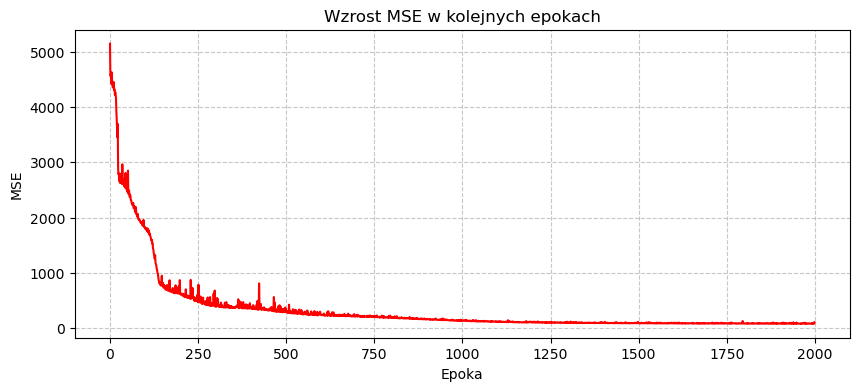

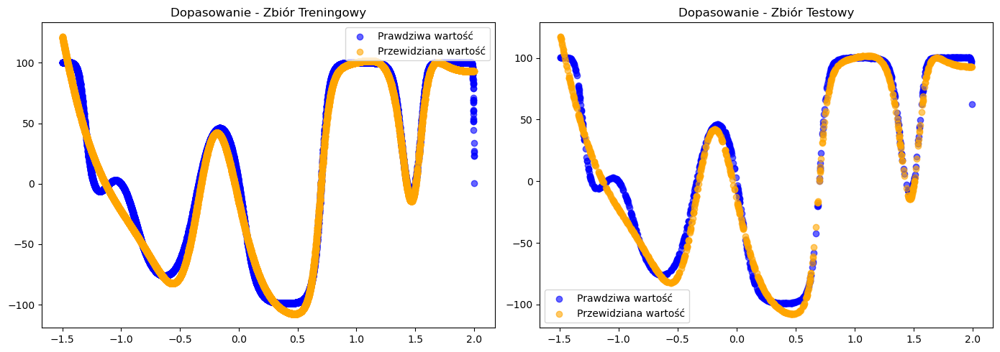

In [227]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2_20, sigmoid_2_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4428.5040
Krok   100 | MSE Trening: 4428.9941
Krok   200 | MSE Trening: 4398.4120
Krok   300 | MSE Trening: 4454.2478
Krok   400 | MSE Trening: 4407.8776
Krok   500 | MSE Trening: 4401.1861
Krok   600 | MSE Trening: 4522.9780
Krok   700 | MSE Trening: 4507.5549
Krok   800 | MSE Trening: 4406.2695
Krok   900 | MSE Trening: 4425.0222
Krok  1000 | MSE Trening: 4420.9095
Krok  1100 | MSE Trening: 4422.0951
Krok  1200 | MSE Trening: 4496.2227
Krok  1300 | MSE Trening: 4412.9677
Krok  1400 | MSE Trening: 4445.1379
Krok  1500 | MSE Trening: 4401.3147
Krok  1600 | MSE Trening: 4558.1959
Krok  1700 | MSE Trening: 4412.6794
Krok  1800 | MSE Trening: 4425.7791
Krok  1900 | MSE Trening: 4404.4061
--------------------------------------------------
MSE treningowe FINALNE: 4405.4478
MSE testowe FINALNE: 4441.1971


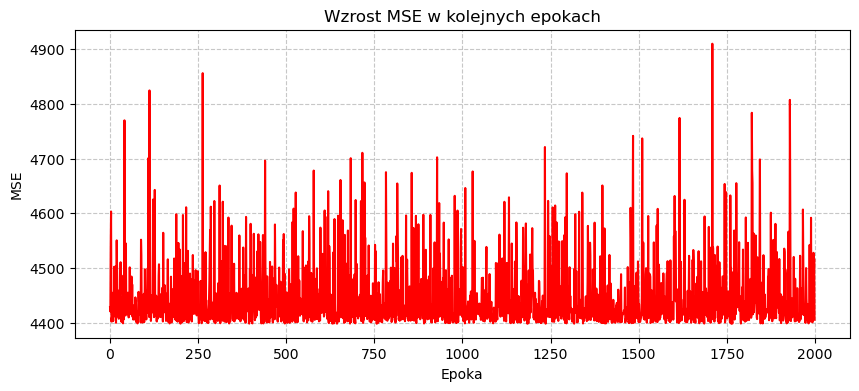

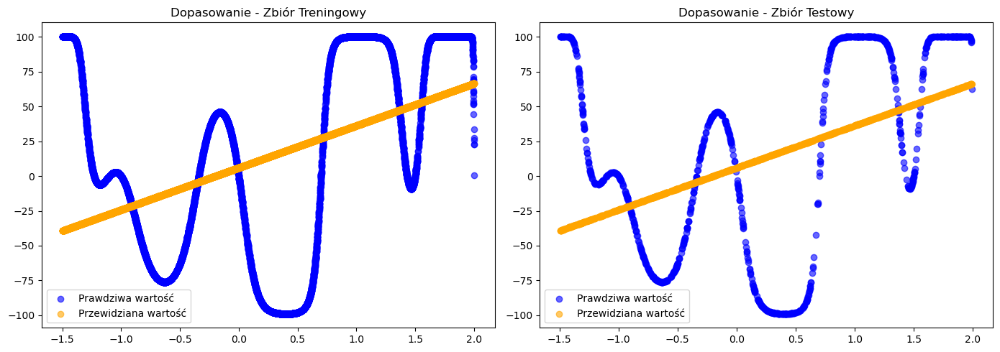

In [228]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_2_5, liniowa_2_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4446.2887
Krok   100 | MSE Trening: 4494.9917
Krok   200 | MSE Trening: 4413.9907
Krok   300 | MSE Trening: 4406.1943
Krok   400 | MSE Trening: 4511.5822
Krok   500 | MSE Trening: 4432.2092
Krok   600 | MSE Trening: 4457.9962
Krok   700 | MSE Trening: 4409.2890
Krok   800 | MSE Trening: 4516.4901
Krok   900 | MSE Trening: 4403.0668
Krok  1000 | MSE Trening: 4446.3577
Krok  1100 | MSE Trening: 4432.7910
Krok  1200 | MSE Trening: 4425.2620
Krok  1300 | MSE Trening: 4405.5821
Krok  1400 | MSE Trening: 4448.6391
Krok  1500 | MSE Trening: 4399.5824
Krok  1600 | MSE Trening: 4401.6032
Krok  1700 | MSE Trening: 4400.1153
Krok  1800 | MSE Trening: 4445.3117
Krok  1900 | MSE Trening: 4399.6991
--------------------------------------------------
MSE treningowe FINALNE: 4437.4186
MSE testowe FINALNE: 4477.4956


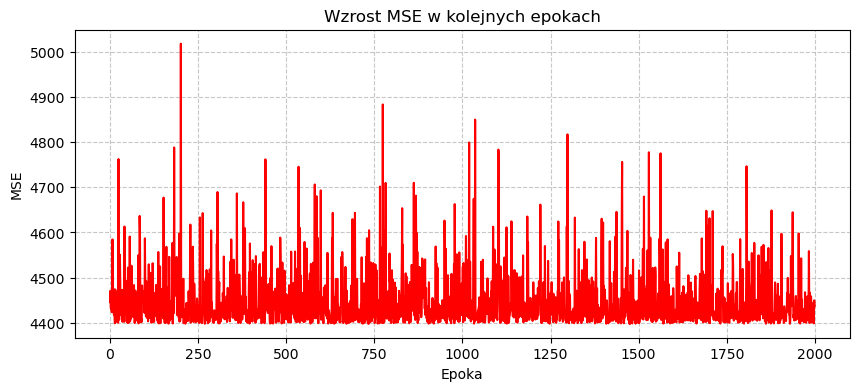

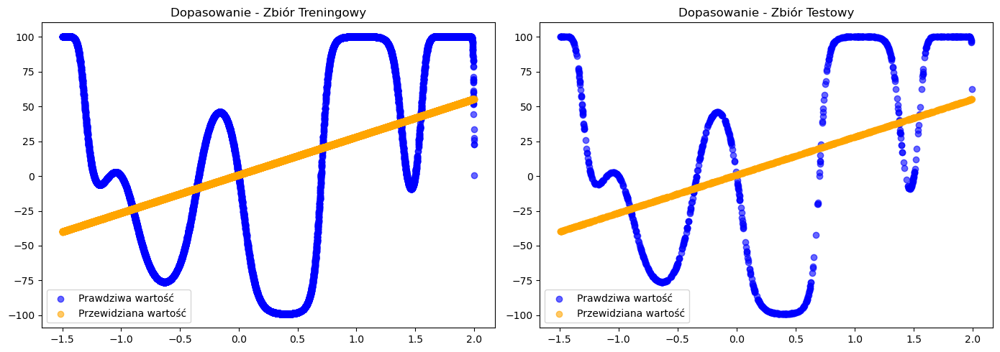

In [229]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_2_10, liniowa_2_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4457.5395
Krok   100 | MSE Trening: 4504.8422
Krok   200 | MSE Trening: 4618.6126
Krok   300 | MSE Trening: 4475.0431
Krok   400 | MSE Trening: 4424.5268
Krok   500 | MSE Trening: 4425.7014
Krok   600 | MSE Trening: 4542.5001
Krok   700 | MSE Trening: 4408.2257
Krok   800 | MSE Trening: 4454.8640
Krok   900 | MSE Trening: 4430.8523
Krok  1000 | MSE Trening: 4448.4082
Krok  1100 | MSE Trening: 4414.9983
Krok  1200 | MSE Trening: 4398.4637
Krok  1300 | MSE Trening: 4417.1340
Krok  1400 | MSE Trening: 4423.8443
Krok  1500 | MSE Trening: 4432.2846
Krok  1600 | MSE Trening: 4468.3449
Krok  1700 | MSE Trening: 4413.2773
Krok  1800 | MSE Trening: 4405.8895
Krok  1900 | MSE Trening: 4461.7912
--------------------------------------------------
MSE treningowe FINALNE: 4414.9485
MSE testowe FINALNE: 4447.6424


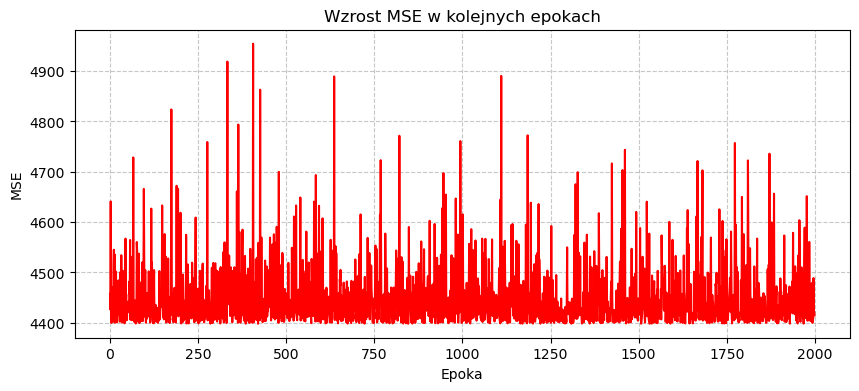

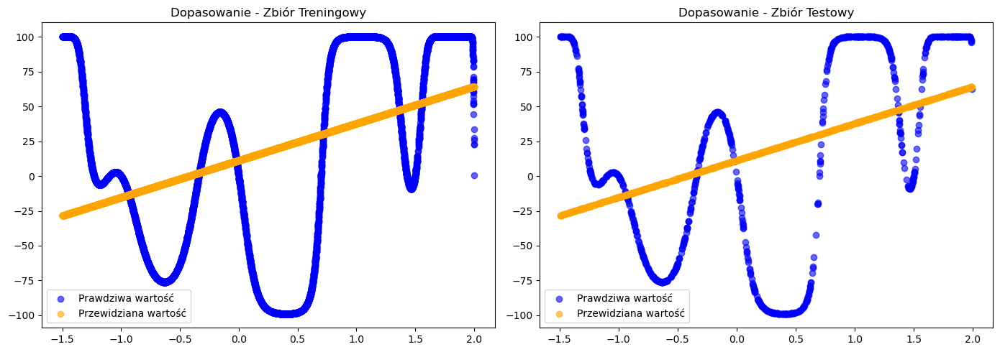

In [230]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_2_20, liniowa_2_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 3209.8563
Krok   100 | MSE Trening: 2651.1831
Krok   200 | MSE Trening: 2682.0626
Krok   300 | MSE Trening: 2722.3056
Krok   400 | MSE Trening: 2577.2472
Krok   500 | MSE Trening: 2553.8631
Krok   600 | MSE Trening: 2587.6487
Krok   700 | MSE Trening: 2745.3222
Krok   800 | MSE Trening: 2701.3440
Krok   900 | MSE Trening: 2580.9544
Krok  1000 | MSE Trening: 2557.0011
Krok  1100 | MSE Trening: 2593.4220
Krok  1200 | MSE Trening: 2657.6069
Krok  1300 | MSE Trening: 2608.4383
Krok  1400 | MSE Trening: 2573.6883
Krok  1500 | MSE Trening: 2564.6097
Krok  1600 | MSE Trening: 2574.1550
Krok  1700 | MSE Trening: 2638.1695
Krok  1800 | MSE Trening: 2580.0896
Krok  1900 | MSE Trening: 2634.3088
--------------------------------------------------
MSE treningowe FINALNE: 2548.9841
MSE testowe FINALNE: 2643.1031


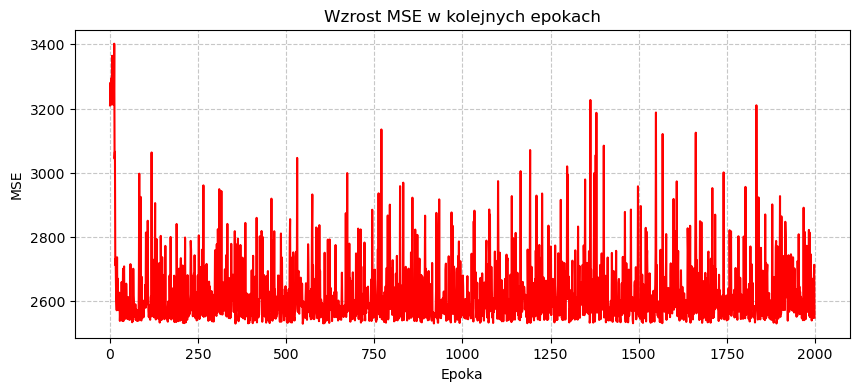

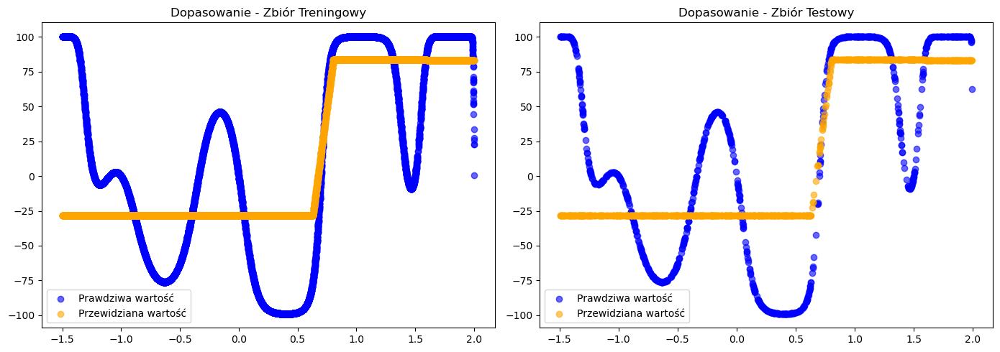

In [231]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_2_5, relu_2_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 3377.6576
Krok   100 | MSE Trening: 1547.2275
Krok   200 | MSE Trening: 1467.7811
Krok   300 | MSE Trening: 1534.4483
Krok   400 | MSE Trening: 1470.6799
Krok   500 | MSE Trening: 1456.3780
Krok   600 | MSE Trening: 1471.1507
Krok   700 | MSE Trening: 1473.2644
Krok   800 | MSE Trening: 1475.9659
Krok   900 | MSE Trening: 1639.0595
Krok  1000 | MSE Trening: 1487.0327
Krok  1100 | MSE Trening: 1493.1636
Krok  1200 | MSE Trening: 1454.5750
Krok  1300 | MSE Trening: 1539.4524
Krok  1400 | MSE Trening: 1471.6719
Krok  1500 | MSE Trening: 1485.8064
Krok  1600 | MSE Trening: 1506.9482
Krok  1700 | MSE Trening: 1478.8691
Krok  1800 | MSE Trening: 1548.4130
Krok  1900 | MSE Trening: 1458.0840
--------------------------------------------------
MSE treningowe FINALNE: 1459.1218
MSE testowe FINALNE: 1499.1549


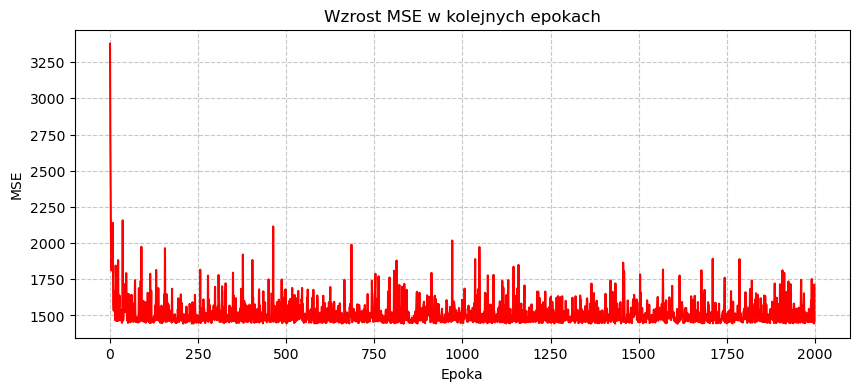

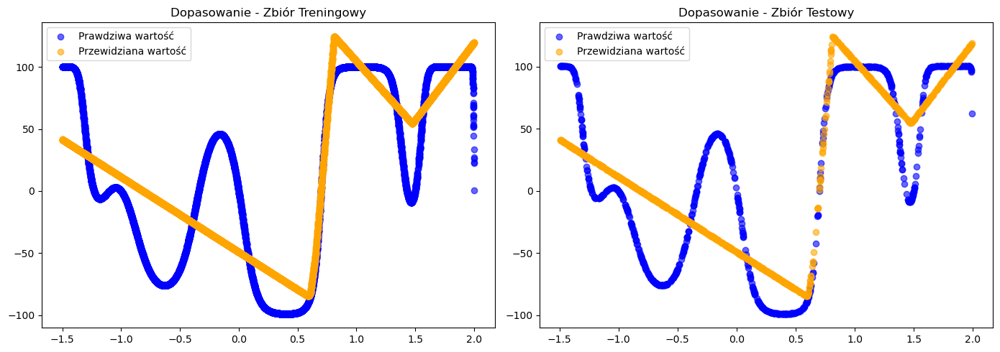

In [232]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_2_10, relu_2_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 2903.9493
Krok   100 | MSE Trening: 239.3739
Krok   200 | MSE Trening:  66.5360
Krok   300 | MSE Trening: 187.8750
Krok   400 | MSE Trening:  99.7847
Krok   500 | MSE Trening:  27.7834
Krok   600 | MSE Trening:  24.2958
Krok   700 | MSE Trening:  23.6853
Krok   800 | MSE Trening:  23.2694
Krok   900 | MSE Trening:  45.8077
Krok  1000 | MSE Trening:  21.6139
Krok  1100 | MSE Trening:  31.5408
Krok  1200 | MSE Trening:  50.2807
Krok  1300 | MSE Trening:  38.9178
Krok  1400 | MSE Trening:  27.3155
Krok  1500 | MSE Trening:  22.6602
Krok  1600 | MSE Trening:  28.5592
Krok  1700 | MSE Trening:  22.6213
Krok  1800 | MSE Trening:  63.4858
Krok  1900 | MSE Trening:  33.5643
--------------------------------------------------
MSE treningowe FINALNE: 27.7395
MSE testowe FINALNE: 24.4324


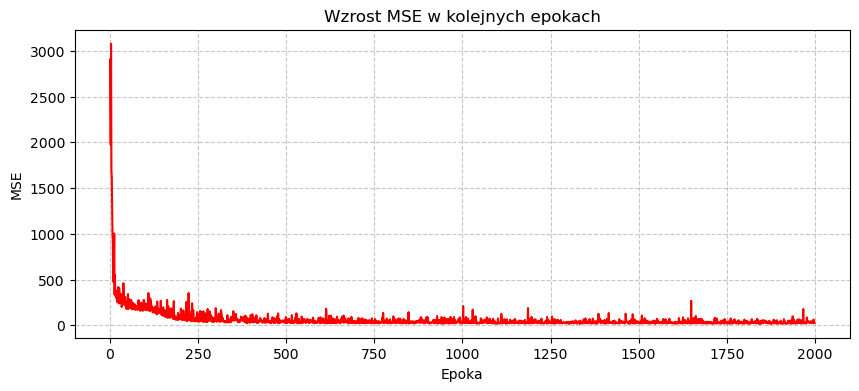

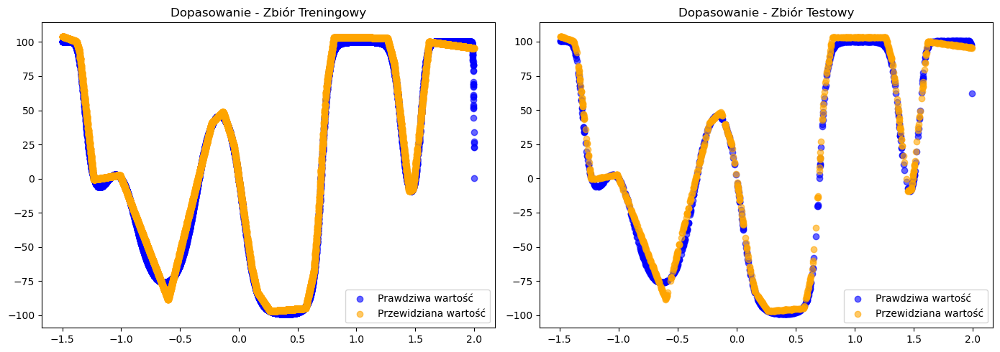

In [233]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_2_20, relu_2_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4620.8784
Krok   100 | MSE Trening: 366.5896
Krok   200 | MSE Trening: 134.5789
Krok   300 | MSE Trening:  80.0305
Krok   400 | MSE Trening:  69.5709
Krok   500 | MSE Trening:  67.8923
Krok   600 | MSE Trening:  49.1145
Krok   700 | MSE Trening:  40.6327
Krok   800 | MSE Trening:  28.7915
Krok   900 | MSE Trening:  25.1545
Krok  1000 | MSE Trening:  18.9020
Krok  1100 | MSE Trening:  18.0471
Krok  1200 | MSE Trening:  16.0910
Krok  1300 | MSE Trening:  14.2985
Krok  1400 | MSE Trening:  14.4509
Krok  1500 | MSE Trening:  13.4148
Krok  1600 | MSE Trening:  12.7768
Krok  1700 | MSE Trening:  14.9443
Krok  1800 | MSE Trening:  13.7928
Krok  1900 | MSE Trening:  12.7209
--------------------------------------------------
MSE treningowe FINALNE: 16.3187
MSE testowe FINALNE: 11.4474


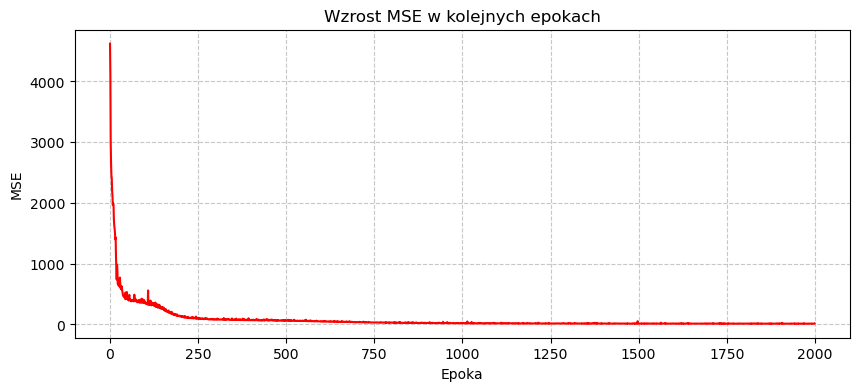

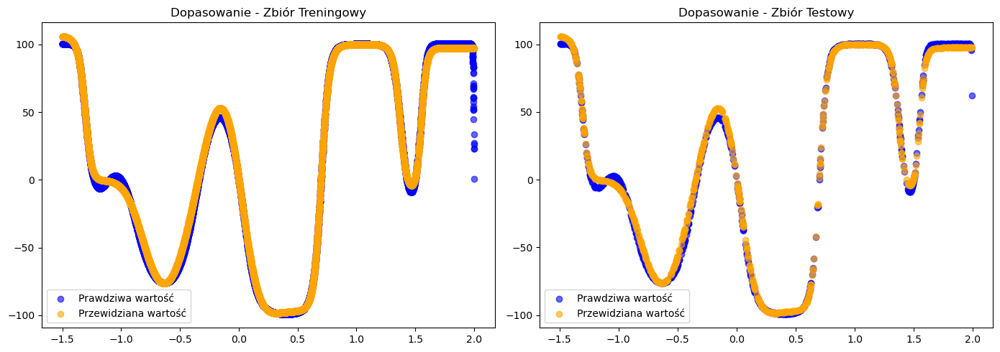

In [234]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2_5, tanh_2_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4385.8381
Krok   100 | MSE Trening: 324.7004
Krok   200 | MSE Trening:  99.0653
Krok   300 | MSE Trening:  85.5421
Krok   400 | MSE Trening:  60.6541
Krok   500 | MSE Trening:  49.8297
Krok   600 | MSE Trening:  13.1835
Krok   700 | MSE Trening:  11.4113
Krok   800 | MSE Trening:  11.5567
Krok   900 | MSE Trening:  10.4355
Krok  1000 | MSE Trening:  10.7115
Krok  1100 | MSE Trening:  11.1137
Krok  1200 | MSE Trening:  11.0963
Krok  1300 | MSE Trening:  11.8932
Krok  1400 | MSE Trening:  11.8751
Krok  1500 | MSE Trening:  12.1205
Krok  1600 | MSE Trening:   9.3734
Krok  1700 | MSE Trening:  10.5753
Krok  1800 | MSE Trening:  11.9032
Krok  1900 | MSE Trening:  11.2853
--------------------------------------------------
MSE treningowe FINALNE: 9.6311
MSE testowe FINALNE: 5.8972


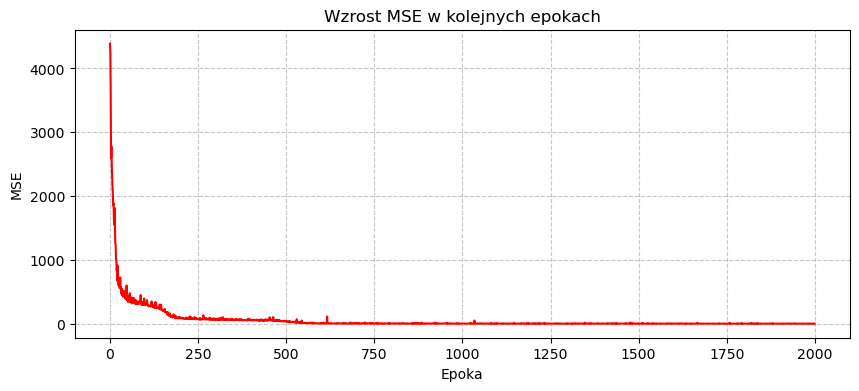

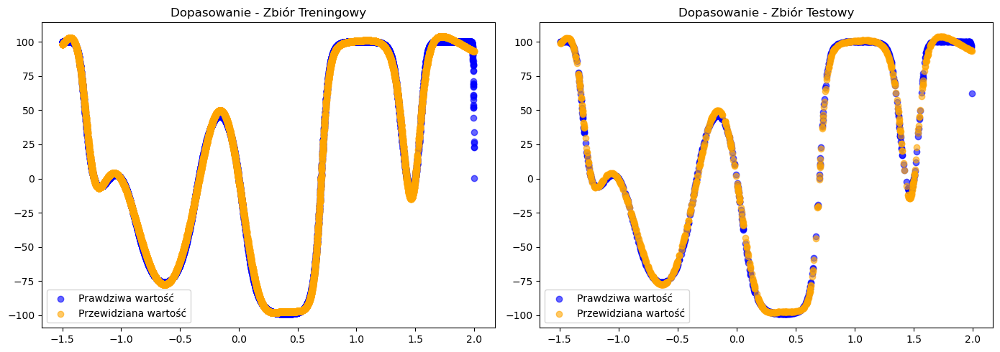

In [235]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2_10, tanh_2_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4407.5552
Krok   100 | MSE Trening: 280.3243
Krok   200 | MSE Trening:  84.7395
Krok   300 | MSE Trening:  73.4688
Krok   400 | MSE Trening:  64.9284
Krok   500 | MSE Trening:  59.6996
Krok   600 | MSE Trening:  36.7531
Krok   700 | MSE Trening:  22.8162
Krok   800 | MSE Trening:  20.3866
Krok   900 | MSE Trening:  16.6327
Krok  1000 | MSE Trening:  15.0749
Krok  1100 | MSE Trening:  10.5088
Krok  1200 | MSE Trening:  11.0404
Krok  1300 | MSE Trening:  10.1022
Krok  1400 | MSE Trening:   9.5196
Krok  1500 | MSE Trening:   8.8744
Krok  1600 | MSE Trening:   9.2202
Krok  1700 | MSE Trening:   9.3725
Krok  1800 | MSE Trening:   8.3645
Krok  1900 | MSE Trening:   9.6285
--------------------------------------------------
MSE treningowe FINALNE: 8.4509
MSE testowe FINALNE: 5.2032


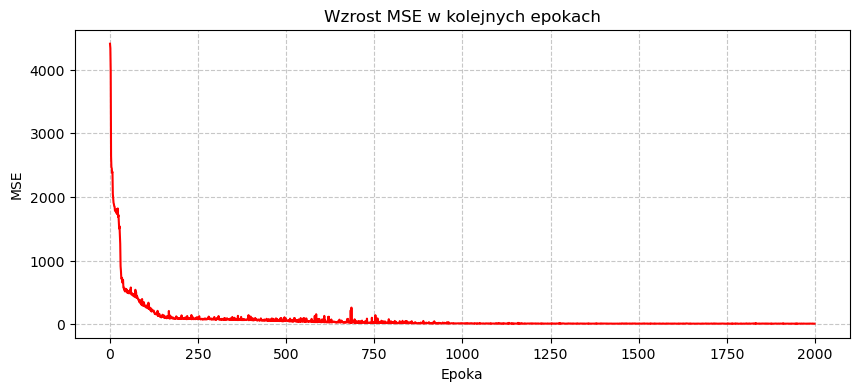

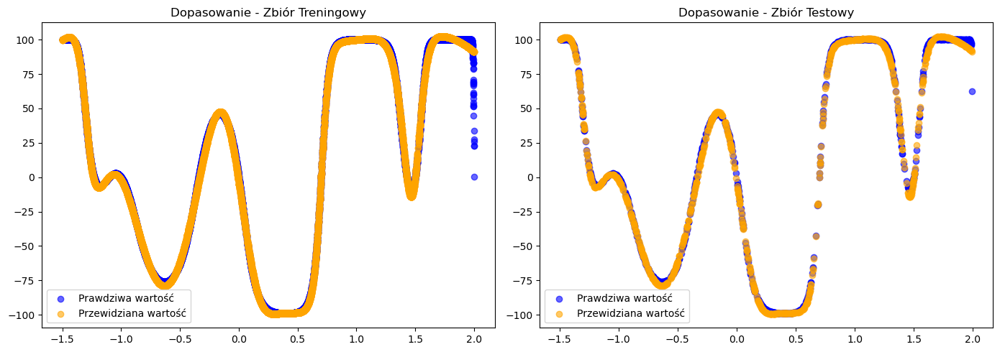

In [236]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2_20, tanh_2_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

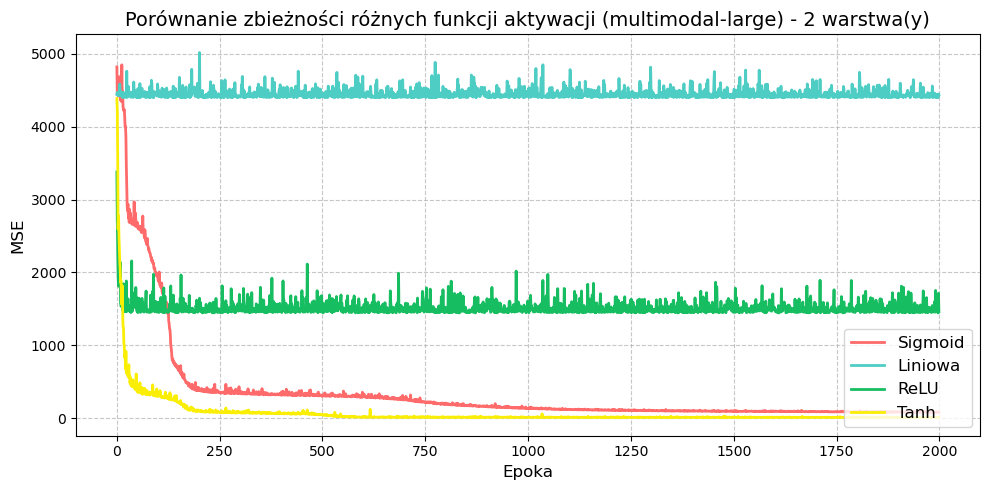

In [237]:
wykres_score('multimodal-large', 'MSE', hist_sigmoid_2_10, hist_liniowa_2_10, hist_relu_2_10, hist_tanh_2_10, 2)

## Trzy warstwy ukryte

Krok     0 | MSE Trening: 5195.1690
Krok   100 | MSE Trening: 1602.7319
Krok   200 | MSE Trening: 485.2767
Krok   300 | MSE Trening: 377.2747
Krok   400 | MSE Trening: 250.6269
Krok   500 | MSE Trening: 218.6750
Krok   600 | MSE Trening: 176.9204
Krok   700 | MSE Trening: 186.3409
Krok   800 | MSE Trening: 154.7155
Krok   900 | MSE Trening: 148.5178
Krok  1000 | MSE Trening: 139.1685
Krok  1100 | MSE Trening: 132.7222
Krok  1200 | MSE Trening: 128.2083
Krok  1300 | MSE Trening: 123.4344
Krok  1400 | MSE Trening: 127.1955
Krok  1500 | MSE Trening: 116.3687
Krok  1600 | MSE Trening: 113.7638
Krok  1700 | MSE Trening: 122.5790
Krok  1800 | MSE Trening: 115.7062
Krok  1900 | MSE Trening: 113.6715
--------------------------------------------------
MSE treningowe FINALNE: 112.5086
MSE testowe FINALNE: 106.7972


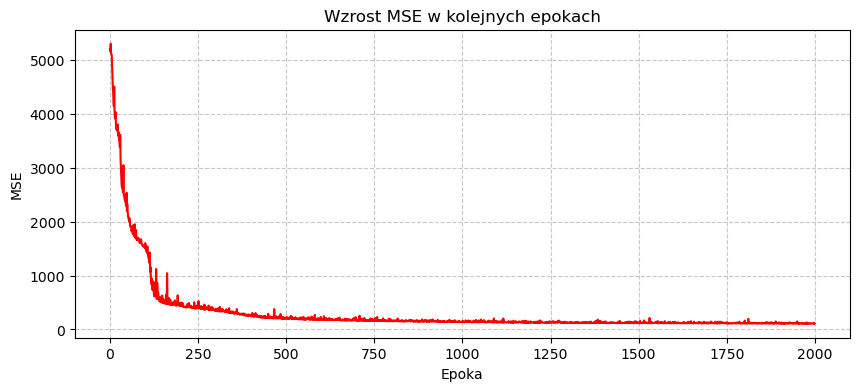

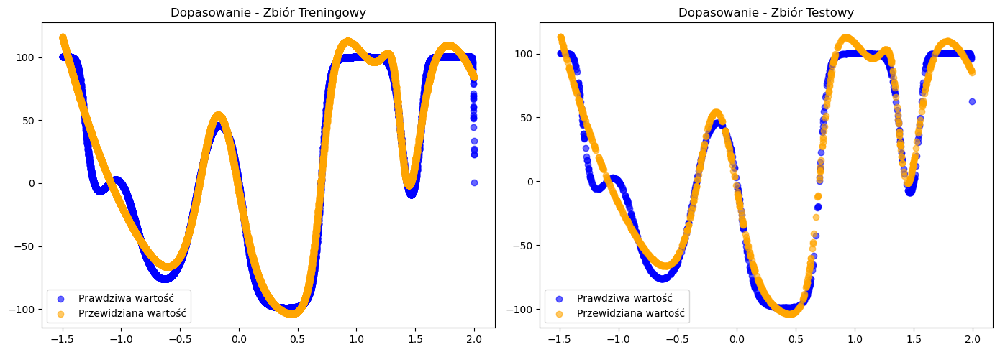

In [238]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3_5, sigmoid_3_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 5245.2861
Krok   100 | MSE Trening: 1637.1364
Krok   200 | MSE Trening: 415.7523
Krok   300 | MSE Trening: 346.7339
Krok   400 | MSE Trening: 348.9244
Krok   500 | MSE Trening: 345.1776
Krok   600 | MSE Trening: 334.8204
Krok   700 | MSE Trening: 312.4169
Krok   800 | MSE Trening: 303.5666
Krok   900 | MSE Trening: 301.6633
Krok  1000 | MSE Trening: 286.0757
Krok  1100 | MSE Trening: 285.4516
Krok  1200 | MSE Trening: 263.4949
Krok  1300 | MSE Trening: 240.8753
Krok  1400 | MSE Trening: 212.6644
Krok  1500 | MSE Trening: 169.1071
Krok  1600 | MSE Trening: 126.2410
Krok  1700 | MSE Trening:  93.4567
Krok  1800 | MSE Trening:  65.9272
Krok  1900 | MSE Trening:  42.6713
--------------------------------------------------
MSE treningowe FINALNE: 35.2214
MSE testowe FINALNE: 30.5986


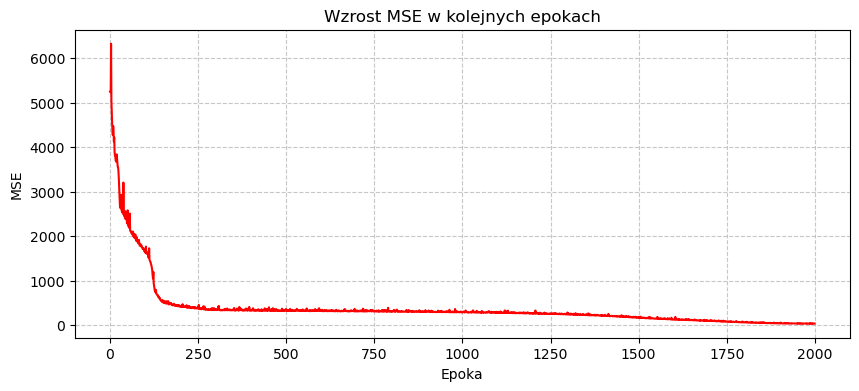

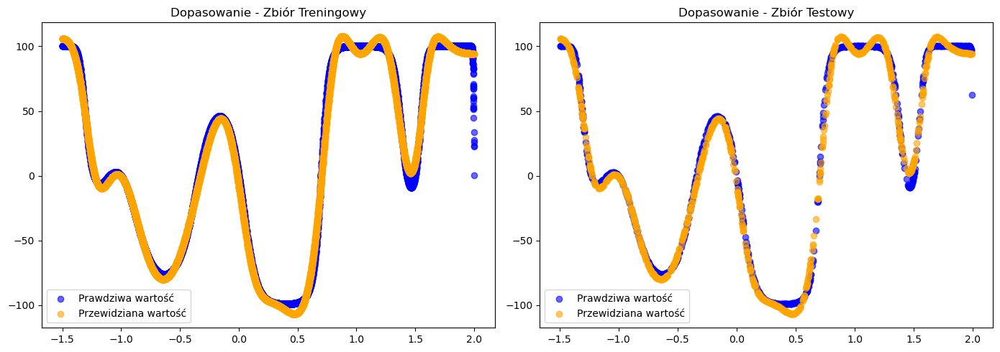

In [239]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 10, 'xavier')
warstwa_4 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3_10, sigmoid_3_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 5173.4423
Krok   100 | MSE Trening: 439.8890
Krok   200 | MSE Trening: 348.2011
Krok   300 | MSE Trening: 339.5611
Krok   400 | MSE Trening: 320.7463
Krok   500 | MSE Trening: 300.0700
Krok   600 | MSE Trening: 306.9038
Krok   700 | MSE Trening: 272.0097
Krok   800 | MSE Trening: 238.7072
Krok   900 | MSE Trening: 204.5010
Krok  1000 | MSE Trening: 138.2489
Krok  1100 | MSE Trening: 102.9553
Krok  1200 | MSE Trening:  92.8287
Krok  1300 | MSE Trening:  83.8671
Krok  1400 | MSE Trening:  77.0299
Krok  1500 | MSE Trening:  68.4413
Krok  1600 | MSE Trening:  66.4866
Krok  1700 | MSE Trening:  59.8180
Krok  1800 | MSE Trening:  52.7720
Krok  1900 | MSE Trening:  49.4566
--------------------------------------------------
MSE treningowe FINALNE: 42.3267
MSE testowe FINALNE: 41.0228


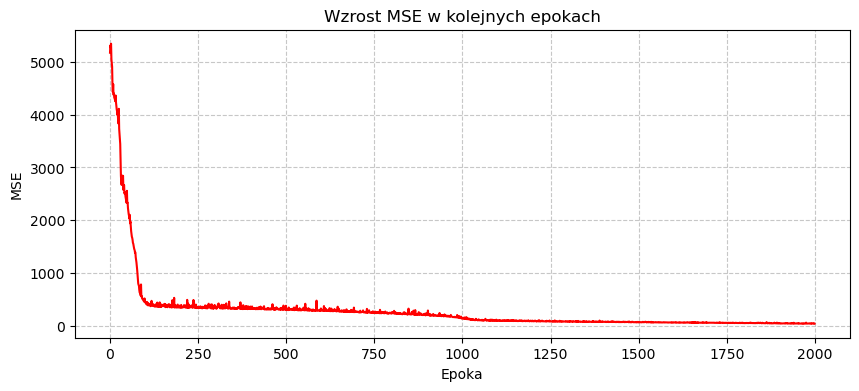

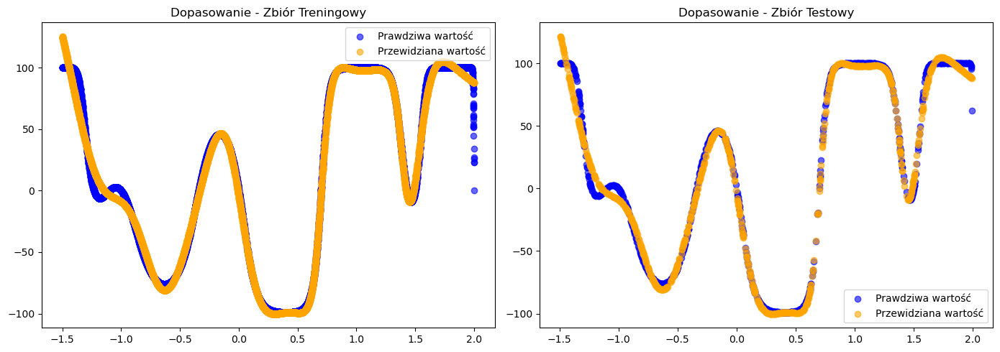

In [240]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 20, 'xavier')
warstwa_4 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3_20, sigmoid_3_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4399.6168
Krok   100 | MSE Trening: 4603.6617
Krok   200 | MSE Trening: 4583.0213
Krok   300 | MSE Trening: 4499.9431
Krok   400 | MSE Trening: 4583.0948
Krok   500 | MSE Trening: 4424.1681
Krok   600 | MSE Trening: 4491.7661
Krok   700 | MSE Trening: 4488.2969
Krok   800 | MSE Trening: 4400.6167
Krok   900 | MSE Trening: 4442.5829
Krok  1000 | MSE Trening: 4409.4925
Krok  1100 | MSE Trening: 4400.0645
Krok  1200 | MSE Trening: 4453.5877
Krok  1300 | MSE Trening: 4436.6656
Krok  1400 | MSE Trening: 4620.6011
Krok  1500 | MSE Trening: 4437.0280
Krok  1600 | MSE Trening: 4415.7820
Krok  1700 | MSE Trening: 4447.0706
Krok  1800 | MSE Trening: 4418.5990
Krok  1900 | MSE Trening: 4415.4129
--------------------------------------------------
MSE treningowe FINALNE: 4516.3236
MSE testowe FINALNE: 4559.7751


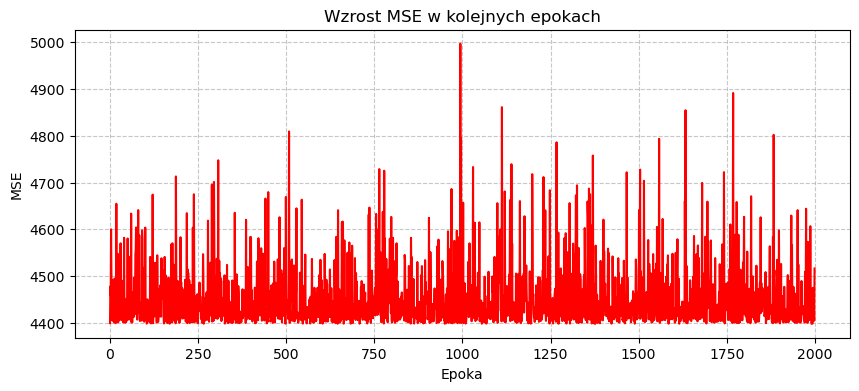

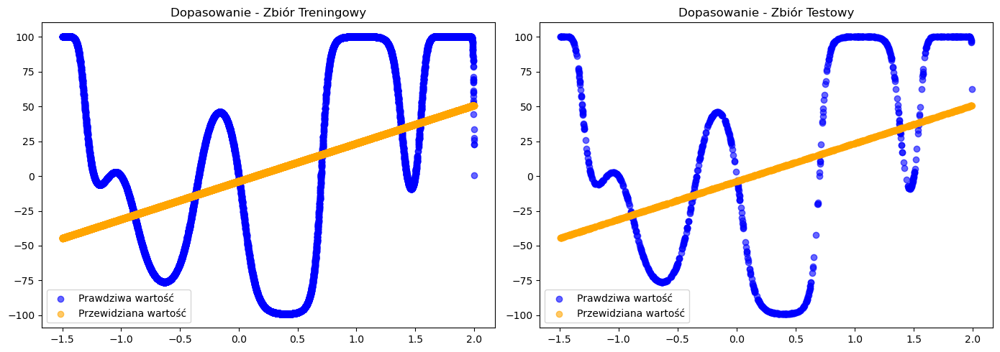

In [241]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3, liniowa(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_3_5, liniowa_3_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4605.2178
Krok   100 | MSE Trening: 4407.5727
Krok   200 | MSE Trening: 4505.6689
Krok   300 | MSE Trening: 4398.8061
Krok   400 | MSE Trening: 4620.3444
Krok   500 | MSE Trening: 4400.6569
Krok   600 | MSE Trening: 4399.6694
Krok   700 | MSE Trening: 4486.0894
Krok   800 | MSE Trening: 4416.9602
Krok   900 | MSE Trening: 4546.0672
Krok  1000 | MSE Trening: 4409.1109
Krok  1100 | MSE Trening: 4420.4814
Krok  1200 | MSE Trening: 4400.1286
Krok  1300 | MSE Trening: 4409.7115
Krok  1400 | MSE Trening: 4448.2155
Krok  1500 | MSE Trening: 4400.1369
Krok  1600 | MSE Trening: 4430.8039
Krok  1700 | MSE Trening: 4401.8614
Krok  1800 | MSE Trening: 4406.4538
Krok  1900 | MSE Trening: 4428.7815
--------------------------------------------------
MSE treningowe FINALNE: 4400.5904
MSE testowe FINALNE: 4436.9057


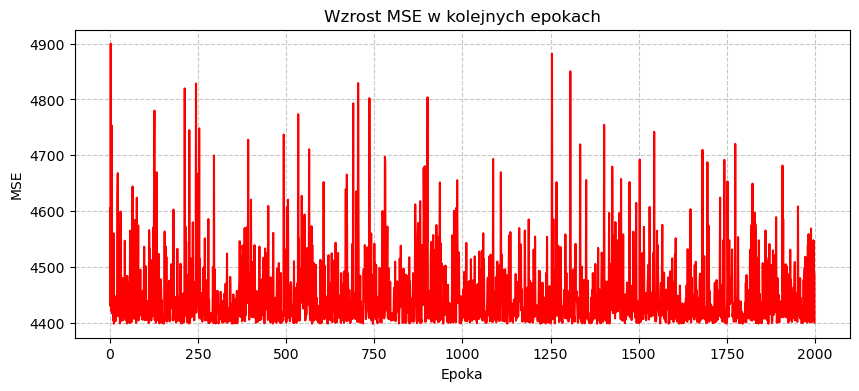

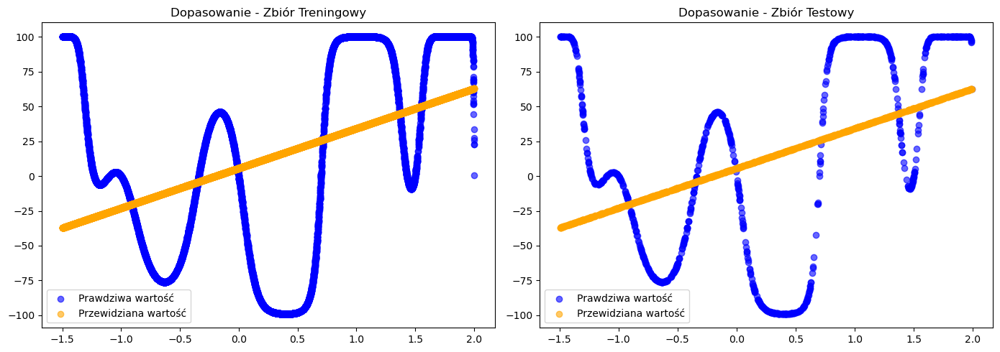

In [242]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 10, 'xavier')
warstwa_4 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3, liniowa(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_3_10, liniowa_3_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4401.3143
Krok   100 | MSE Trening: 4442.7988
Krok   200 | MSE Trening: 4613.7589
Krok   300 | MSE Trening: 4497.2401
Krok   400 | MSE Trening: 4400.0522
Krok   500 | MSE Trening: 4400.8815
Krok   600 | MSE Trening: 4427.5450
Krok   700 | MSE Trening: 4413.5728
Krok   800 | MSE Trening: 4448.4225
Krok   900 | MSE Trening: 4399.0036
Krok  1000 | MSE Trening: 4416.2031
Krok  1100 | MSE Trening: 4456.3544
Krok  1200 | MSE Trening: 4483.1320
Krok  1300 | MSE Trening: 4411.4810
Krok  1400 | MSE Trening: 4399.1559
Krok  1500 | MSE Trening: 4486.3390
Krok  1600 | MSE Trening: 4447.8363
Krok  1700 | MSE Trening: 4408.2922
Krok  1800 | MSE Trening: 4416.8958
Krok  1900 | MSE Trening: 4432.5553
--------------------------------------------------
MSE treningowe FINALNE: 4445.2152
MSE testowe FINALNE: 4485.4408


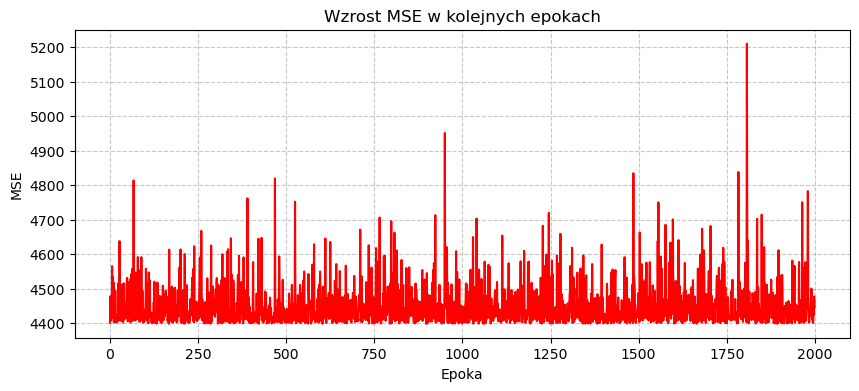

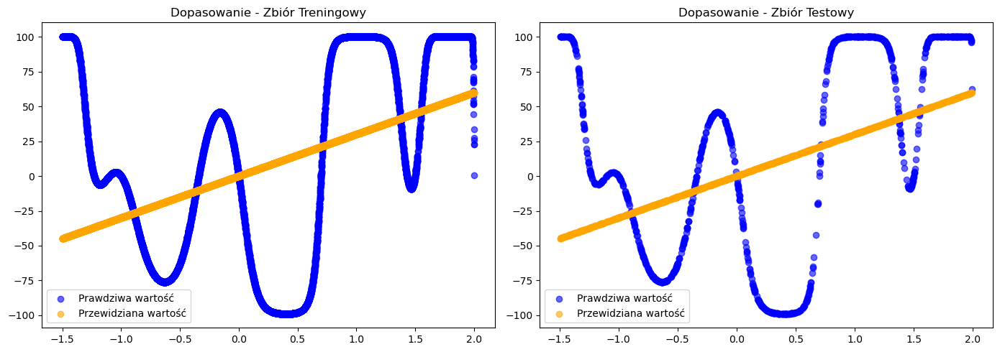

In [243]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 20, 'xavier')
warstwa_4 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, liniowa(), warstwa_2, liniowa(), warstwa_3, liniowa(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_liniowa_3_20, liniowa_3_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 5193.3635
Krok   100 | MSE Trening: 5177.6161
Krok   200 | MSE Trening: 5193.1904
Krok   300 | MSE Trening: 5192.1180
Krok   400 | MSE Trening: 5182.8165
Krok   500 | MSE Trening: 5177.6653
Krok   600 | MSE Trening: 5177.5109
Krok   700 | MSE Trening: 5186.8783
Krok   800 | MSE Trening: 5191.7797
Krok   900 | MSE Trening: 5183.8792
Krok  1000 | MSE Trening: 5252.0412
Krok  1100 | MSE Trening: 5276.1220
Krok  1200 | MSE Trening: 5181.2810
Krok  1300 | MSE Trening: 5214.0333
Krok  1400 | MSE Trening: 5178.4069
Krok  1500 | MSE Trening: 5225.7904
Krok  1600 | MSE Trening: 5182.8317
Krok  1700 | MSE Trening: 5177.3880
Krok  1800 | MSE Trening: 5211.6816
Krok  1900 | MSE Trening: 5178.7927
--------------------------------------------------
MSE treningowe FINALNE: 5228.8312
MSE testowe FINALNE: 5269.0799


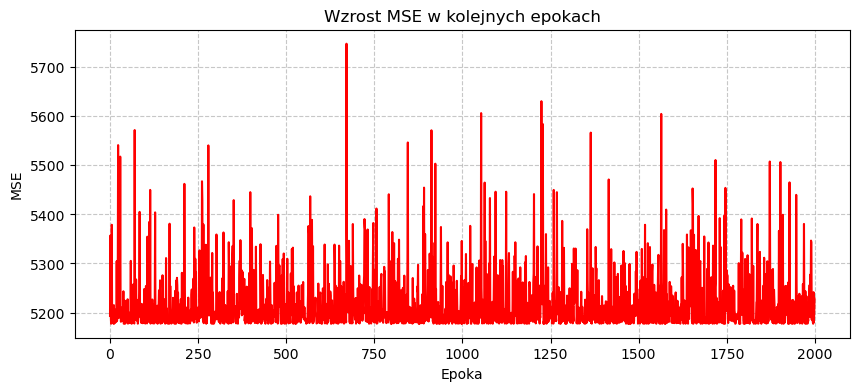

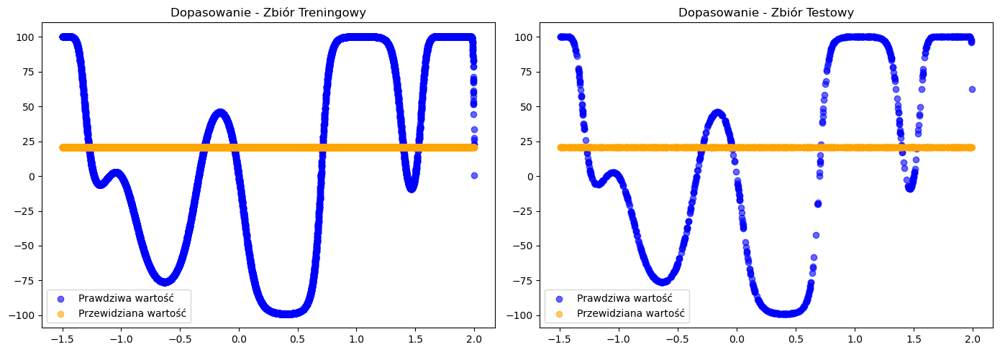

In [244]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3, relu(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_3_5, relu_3_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 2813.9365
Krok   100 | MSE Trening: 542.8026
Krok   200 | MSE Trening:  88.8563
Krok   300 | MSE Trening:  99.0530
Krok   400 | MSE Trening:  95.4701
Krok   500 | MSE Trening:  94.7679
Krok   600 | MSE Trening:  82.6052
Krok   700 | MSE Trening:  89.5952
Krok   800 | MSE Trening: 114.0152
Krok   900 | MSE Trening: 117.5160
Krok  1000 | MSE Trening: 104.2920
Krok  1100 | MSE Trening:  93.1482
Krok  1200 | MSE Trening:  87.6213
Krok  1300 | MSE Trening:  83.0437
Krok  1400 | MSE Trening:  80.6694
Krok  1500 | MSE Trening:  85.6989
Krok  1600 | MSE Trening:  88.2518
Krok  1700 | MSE Trening: 157.5698
Krok  1800 | MSE Trening: 109.1068
Krok  1900 | MSE Trening:  77.4224
--------------------------------------------------
MSE treningowe FINALNE: 89.3238
MSE testowe FINALNE: 89.2581


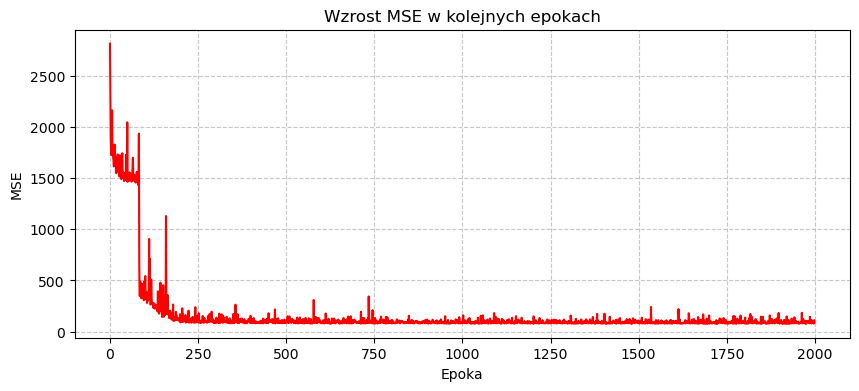

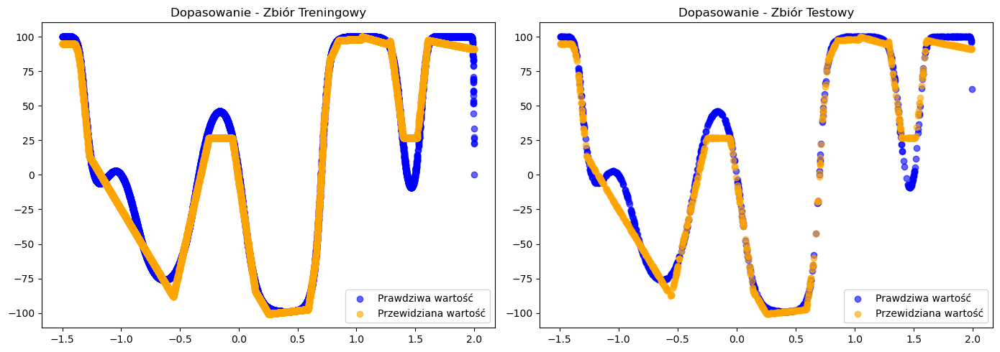

In [245]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 10, 'xavier')
warstwa_4 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3, relu(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_3_10, relu_3_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 3371.8286
Krok   100 | MSE Trening:  48.8826
Krok   200 | MSE Trening:  16.7251
Krok   300 | MSE Trening:   9.5661
Krok   400 | MSE Trening:  20.4289
Krok   500 | MSE Trening:  12.3686
Krok   600 | MSE Trening:  13.3768
Krok   700 | MSE Trening:  12.7481
Krok   800 | MSE Trening:  13.4841
Krok   900 | MSE Trening:  10.1886
Krok  1000 | MSE Trening:  23.5830
Krok  1100 | MSE Trening:   6.4651
Krok  1200 | MSE Trening:   9.5115
Krok  1300 | MSE Trening:   6.5191
Krok  1400 | MSE Trening:  19.2296
Krok  1500 | MSE Trening:  15.8531
Krok  1600 | MSE Trening:  17.9549
Krok  1700 | MSE Trening:  11.7316
Krok  1800 | MSE Trening:  14.6468
Krok  1900 | MSE Trening:   9.1453
--------------------------------------------------
MSE treningowe FINALNE: 10.9766
MSE testowe FINALNE: 7.3439


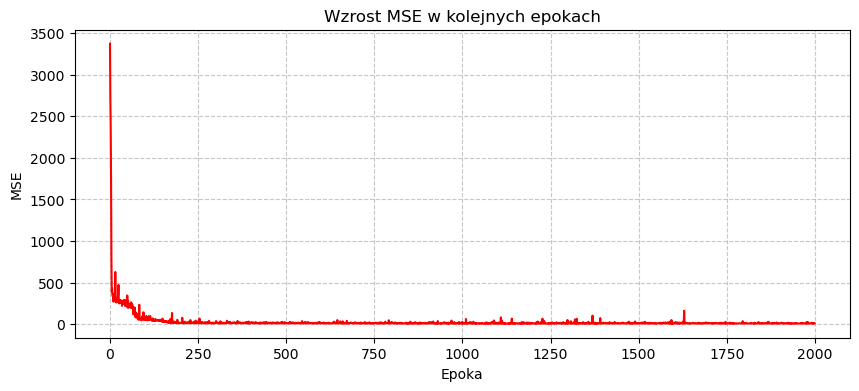

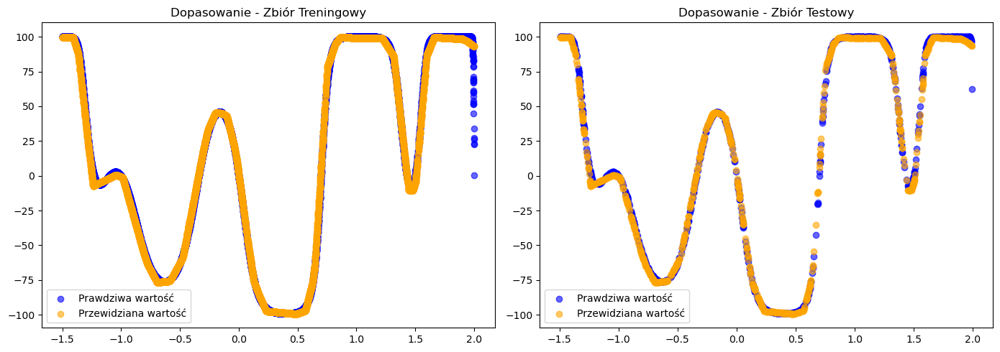

In [246]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 20, 'xavier')
warstwa_4 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, relu(), warstwa_3, relu(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_relu_3_20, relu_3_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4216.3935
Krok   100 | MSE Trening:  65.6070
Krok   200 | MSE Trening:  15.3350
Krok   300 | MSE Trening:  10.6394
Krok   400 | MSE Trening:   9.8758
Krok   500 | MSE Trening:   9.3761
Krok   600 | MSE Trening:  11.0865
Krok   700 | MSE Trening:   9.9271
Krok   800 | MSE Trening:   9.8225
Krok   900 | MSE Trening:   9.0243
Krok  1000 | MSE Trening:   9.1575
Krok  1100 | MSE Trening:   9.1773
Krok  1200 | MSE Trening:  14.7320
Krok  1300 | MSE Trening:   8.7322
Krok  1400 | MSE Trening:   9.3908
Krok  1500 | MSE Trening:   8.8628
Krok  1600 | MSE Trening:   9.0753
Krok  1700 | MSE Trening:   9.1204
Krok  1800 | MSE Trening:   9.1042
Krok  1900 | MSE Trening:   8.6318
--------------------------------------------------
MSE treningowe FINALNE: 8.7517
MSE testowe FINALNE: 5.2380


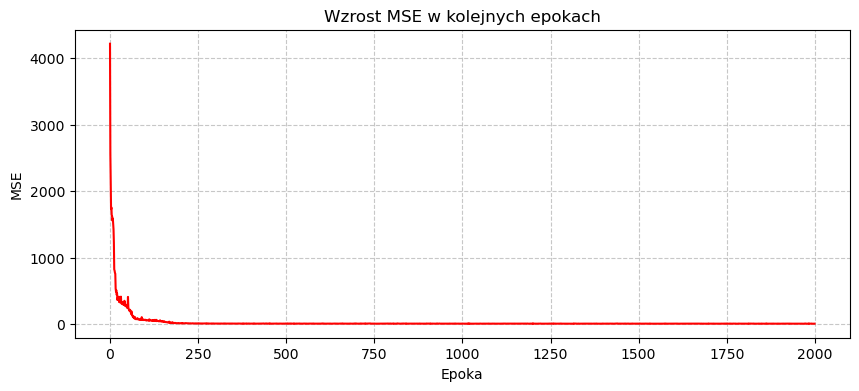

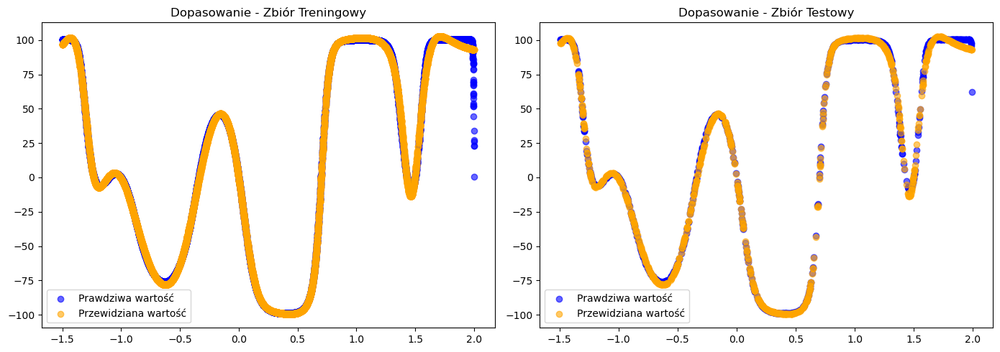

In [247]:
warstwa_1 = warstwa_liniowa(1, 5, 'xavier')
warstwa_2 = warstwa_liniowa(5, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3_5, tanh_3_5 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4181.9231
Krok   100 | MSE Trening: 120.8220
Krok   200 | MSE Trening:   9.2842
Krok   300 | MSE Trening:  11.6802
Krok   400 | MSE Trening:   8.3274
Krok   500 | MSE Trening:   8.2697
Krok   600 | MSE Trening:   8.0992
Krok   700 | MSE Trening:   7.5059
Krok   800 | MSE Trening:   7.4826
Krok   900 | MSE Trening:   7.2134
Krok  1000 | MSE Trening:   7.5447
Krok  1100 | MSE Trening:   7.7209
Krok  1200 | MSE Trening:   7.5825
Krok  1300 | MSE Trening:   6.7719
Krok  1400 | MSE Trening:   6.8369
Krok  1500 | MSE Trening:   7.1779
Krok  1600 | MSE Trening:   7.0560
Krok  1700 | MSE Trening:   6.2416
Krok  1800 | MSE Trening:   6.0697
Krok  1900 | MSE Trening:   6.0327
--------------------------------------------------
MSE treningowe FINALNE: 5.9455
MSE testowe FINALNE: 1.8433


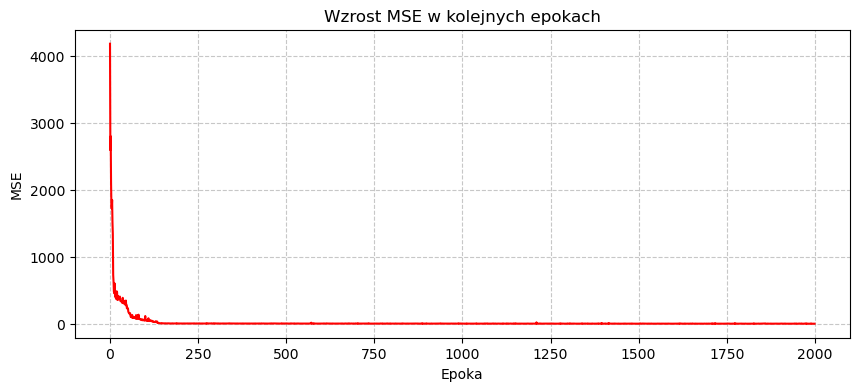

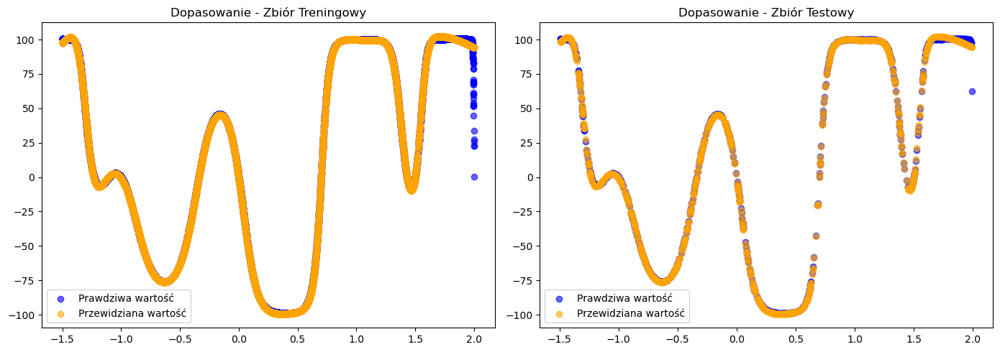

In [248]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 10, 'xavier')
warstwa_4 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3_10, tanh_3_10 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 4032.4581
Krok   100 | MSE Trening:  39.9940
Krok   200 | MSE Trening:   9.1147
Krok   300 | MSE Trening:   8.9035
Krok   400 | MSE Trening:  10.8060
Krok   500 | MSE Trening:   8.4033
Krok   600 | MSE Trening:   8.3243
Krok   700 | MSE Trening:   7.4012
Krok   800 | MSE Trening:   9.8847
Krok   900 | MSE Trening:   6.9680
Krok  1000 | MSE Trening:   6.6590
Krok  1100 | MSE Trening:   6.4955
Krok  1200 | MSE Trening:   6.9293
Krok  1300 | MSE Trening:   6.2367
Krok  1400 | MSE Trening:   6.6979
Krok  1500 | MSE Trening:   6.9372
Krok  1600 | MSE Trening:   5.9641
Krok  1700 | MSE Trening:   6.7417
Krok  1800 | MSE Trening:   6.4258
Krok  1900 | MSE Trening:   5.8797
--------------------------------------------------
MSE treningowe FINALNE: 5.9561
MSE testowe FINALNE: 1.8630


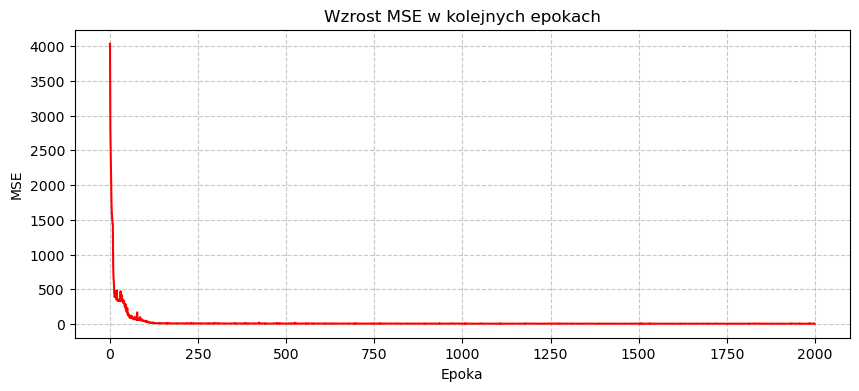

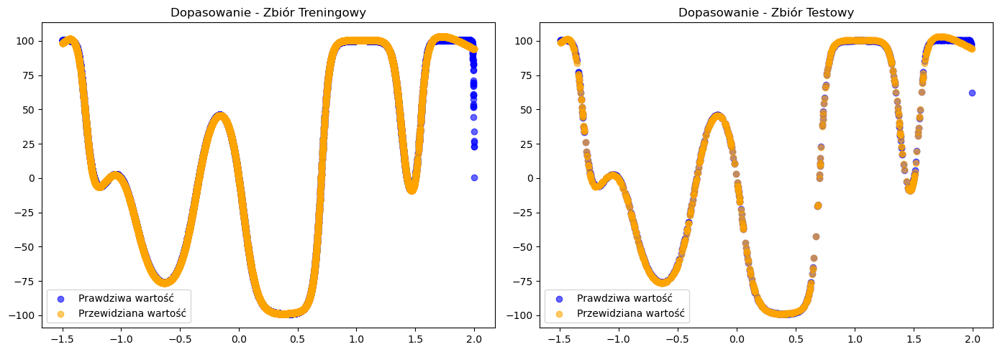

In [249]:
warstwa_1 = warstwa_liniowa(1, 20, 'xavier')
warstwa_2 = warstwa_liniowa(20, 20, 'xavier')
warstwa_3 = warstwa_liniowa(20, 20, 'xavier')
warstwa_4 = warstwa_liniowa(20, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3_20, tanh_3_20 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=MSE, regresja=True, test=True)

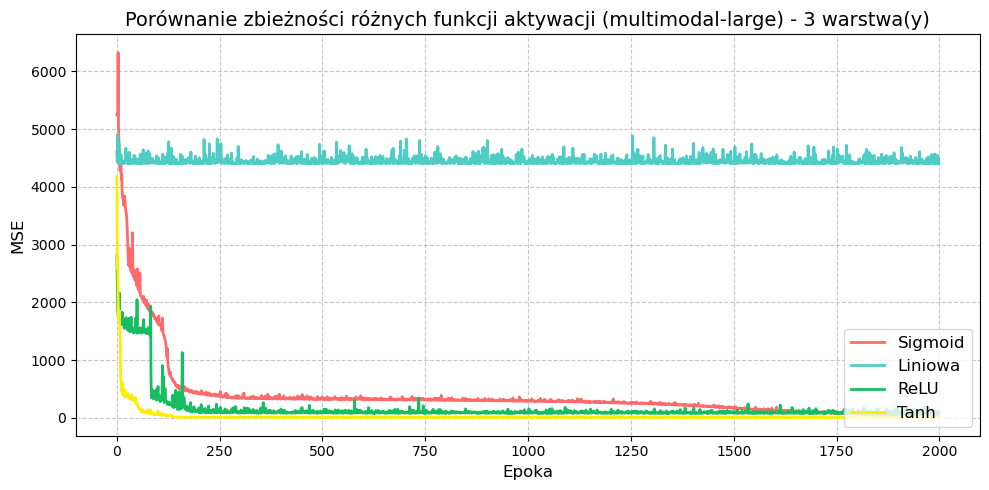

In [250]:
wykres_score('multimodal-large', 'MSE', hist_sigmoid_3_10, hist_liniowa_3_10, hist_relu_3_10, hist_tanh_3_10, 3)

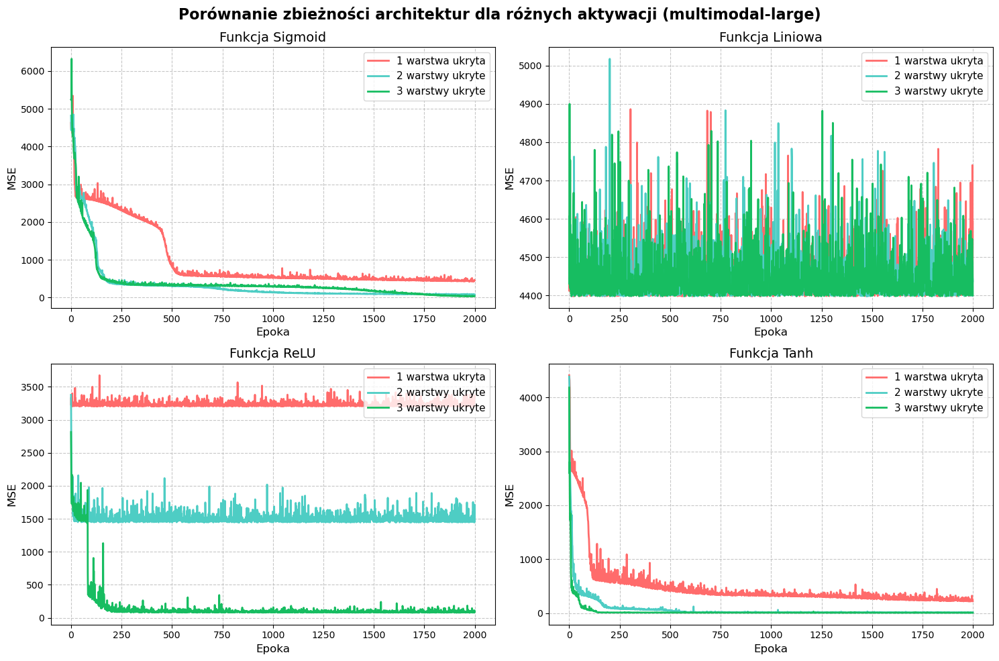

In [251]:
# wszystko na 10 neuronach
historie_do_wykresu = {
    'Sigmoid': (hist_sigmoid_1_10, hist_sigmoid_2_10, hist_sigmoid_3_10),
    'Liniowa': (hist_liniowa_1_10, hist_liniowa_2_10, hist_liniowa_3_10),
    'ReLU':    (hist_relu_1_10, hist_relu_2_10, hist_relu_3_10),
    'Tanh':    (hist_tanh_1_10, hist_tanh_2_10, hist_tanh_3_10)
}

wykresy_warstwy(historie_do_wykresu, zbior="multimodal-large", score="MSE")

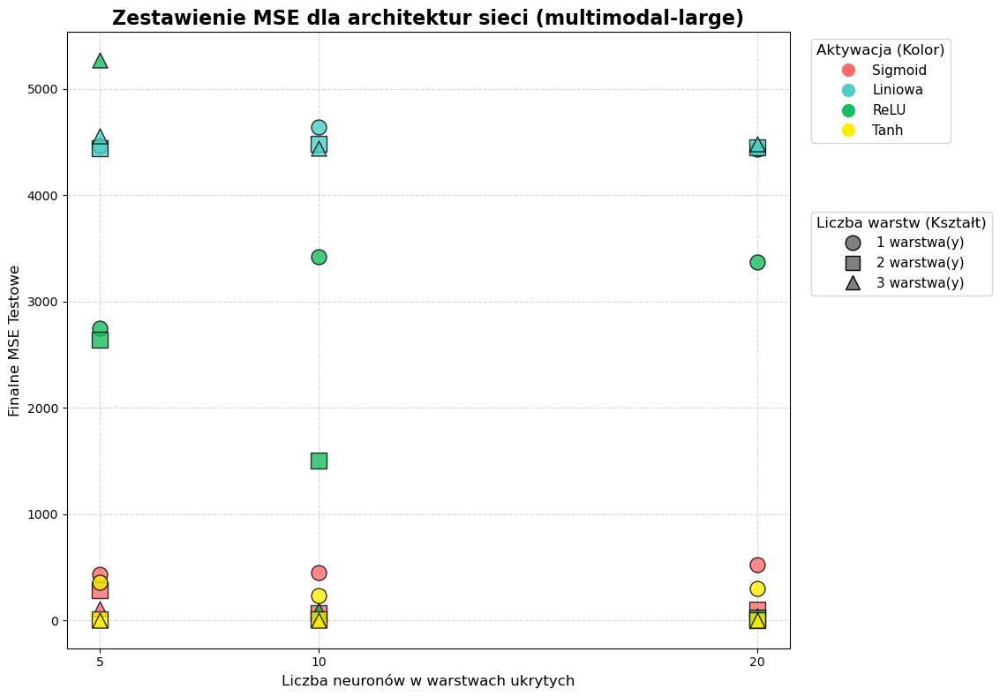

In [252]:
wyniki_mse = {
    'Sigmoid': {
        1: {5: sigmoid_1_5, 10: sigmoid_1_10, 20: sigmoid_1_20},
        2: {5: sigmoid_2_5, 10: sigmoid_2_10, 20: sigmoid_2_20},
        3: {5: sigmoid_3_5, 10: sigmoid_3_10, 20: sigmoid_3_20}
    },
    'Liniowa': {
        1: {5: liniowa_1_5, 10: liniowa_1_10, 20: liniowa_1_20},
        2: {5: liniowa_2_5, 10: liniowa_2_10, 20: liniowa_2_20},
        3: {5: liniowa_3_5, 10: liniowa_3_10, 20: liniowa_3_20}
    },
    'ReLU': {
        1: {5: relu_1_5, 10: relu_1_10, 20: relu_1_20},
        2: {5: relu_2_5, 10: relu_2_10, 20: relu_2_20},
        3: {5: relu_3_5, 10: relu_3_10, 20: relu_3_20}
    },
    'Tanh': {
        1: {5: tanh_1_5, 10: tanh_1_10, 20: tanh_1_20},
        2: {5: tanh_2_5, 10: tanh_2_10, 20: tanh_2_20},
        3: {5: tanh_3_5, 10: tanh_3_10, 20: tanh_3_20}
    }
}

porownanie_scatter(wyniki_mse, zbior="multimodal-large")

# Dane steps-large

In [317]:
steps_large_test = pd.read_csv("mio1/regression/steps-large-test.csv")
steps_large_train = pd.read_csv("mio1/regression/steps-large-training.csv")
X_train = steps_large_train[['x']].to_numpy()
y_train = steps_large_train[['y']].to_numpy()
X_test = steps_large_test[['x']].to_numpy()
y_test = steps_large_test[['y']].to_numpy()

## Dwie warstwy ukryte

Krok     0 | MSE Trening: 3906.6926
Krok   100 | MSE Trening: 477.8076
Krok   200 | MSE Trening: 479.6619
Krok   300 | MSE Trening: 481.3798
Krok   400 | MSE Trening: 478.6286
Krok   500 | MSE Trening: 478.9387
Krok   600 | MSE Trening: 482.6871
Krok   700 | MSE Trening: 522.5796
Krok   800 | MSE Trening: 478.7069
Krok   900 | MSE Trening: 476.5604
Krok  1000 | MSE Trening: 470.0063
Krok  1100 | MSE Trening: 469.9684
Krok  1200 | MSE Trening: 464.7227
Krok  1300 | MSE Trening: 448.0527
Krok  1400 | MSE Trening: 450.3090
Krok  1500 | MSE Trening: 426.0986
Krok  1600 | MSE Trening: 424.3300
Krok  1700 | MSE Trening: 416.4477
Krok  1800 | MSE Trening: 405.0696
Krok  1900 | MSE Trening: 396.2973
Krok  2000 | MSE Trening: 372.1456
Krok  2100 | MSE Trening: 380.3720
Krok  2200 | MSE Trening: 387.6875
Krok  2300 | MSE Trening: 332.4876
Krok  2400 | MSE Trening: 326.0841
Krok  2500 | MSE Trening: 441.6300
Krok  2600 | MSE Trening: 320.3985
Krok  2700 | MSE Trening: 318.2577
Krok  2800 | MSE Tr

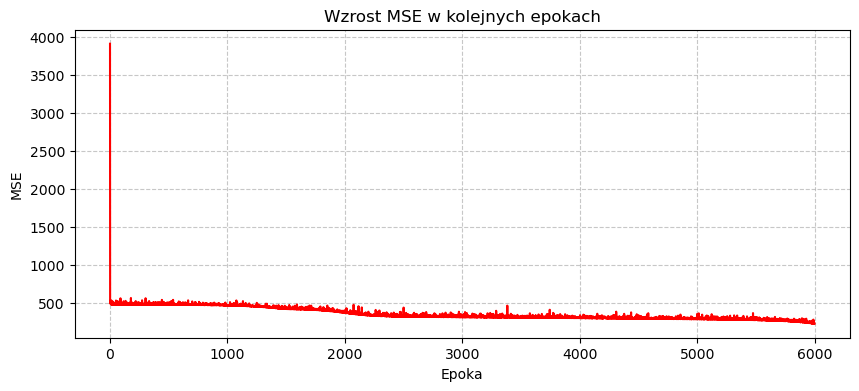

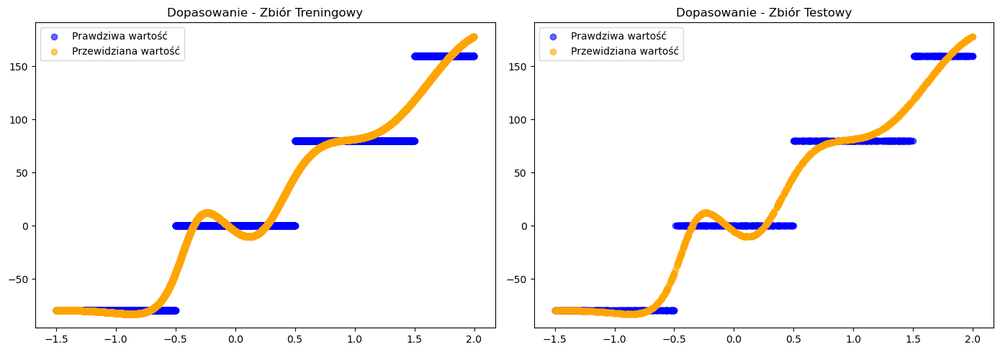

In [318]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2, sigmoid_2 = train(X_train, y_train, X_test, y_test, model, 6000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 556.0528
Krok   100 | MSE Trening: 482.5806
Krok   200 | MSE Trening: 496.6397
Krok   300 | MSE Trening: 417.6276
Krok   400 | MSE Trening: 388.3663
Krok   500 | MSE Trening: 303.3868
Krok   600 | MSE Trening: 248.9447
Krok   700 | MSE Trening: 174.2327
Krok   800 | MSE Trening: 117.8599
Krok   900 | MSE Trening: 109.0207
Krok  1000 | MSE Trening:  96.3383
Krok  1100 | MSE Trening:  83.1138
Krok  1200 | MSE Trening:  75.7931
Krok  1300 | MSE Trening:  70.1624
Krok  1400 | MSE Trening:  67.9312
Krok  1500 | MSE Trening:  61.6356
Krok  1600 | MSE Trening:  58.9227
Krok  1700 | MSE Trening:  56.6217
Krok  1800 | MSE Trening:  53.2267
Krok  1900 | MSE Trening:  50.8730
Krok  2000 | MSE Trening:  49.1690
Krok  2100 | MSE Trening:  46.3050
Krok  2200 | MSE Trening:  44.4029
Krok  2300 | MSE Trening:  43.0791
Krok  2400 | MSE Trening:  46.7068
Krok  2500 | MSE Trening:  41.9475
Krok  2600 | MSE Trening:  42.0082
Krok  2700 | MSE Trening:  41.1117
Krok  2800 | MSE Tre

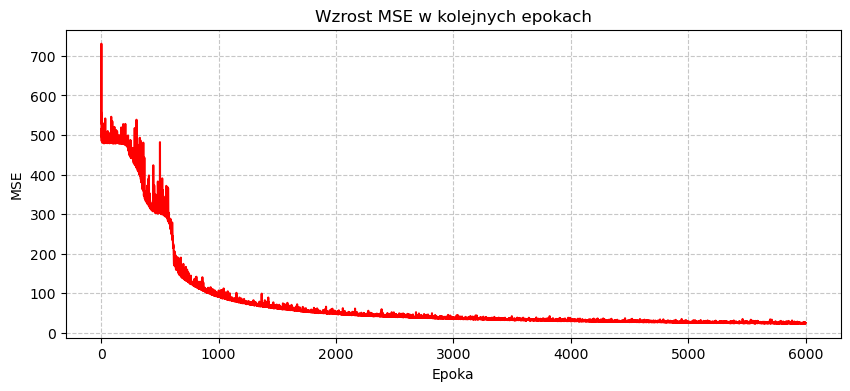

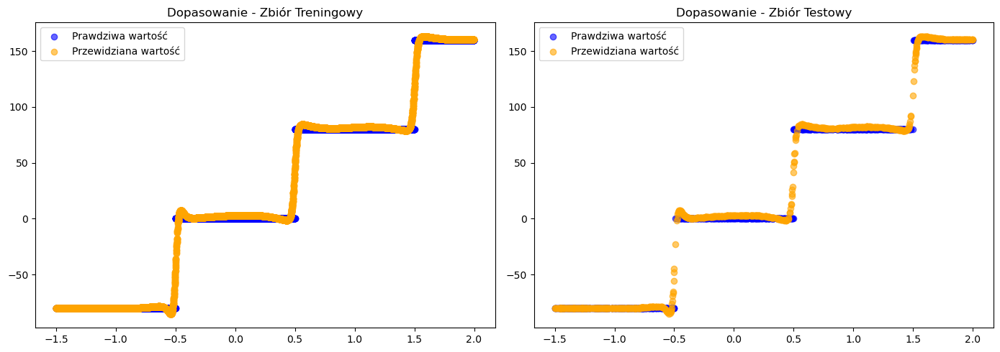

In [319]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2, tanh_2 = train(X_train, y_train, X_test, y_test, model, 6000, 64, funkcja_straty=MSE, regresja=True, test=True)

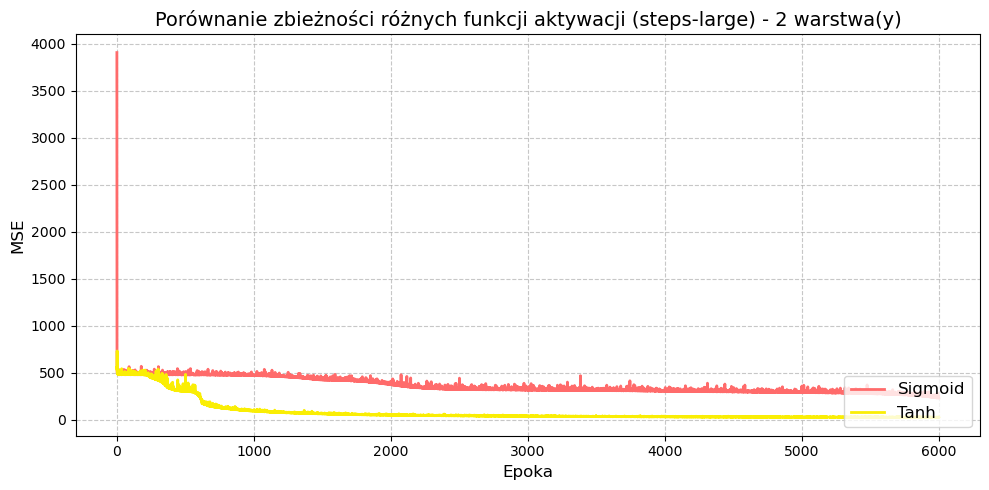

In [320]:
wykres_score('steps-large', 'MSE', hist_tanh=hist_tanh_2, hist_sigmoid=hist_sigmoid_2, warstwa=2)

## Trzy warstwy ukryte

Krok     0 | MSE Trening: 6759.7671
Krok   100 | MSE Trening: 496.9778
Krok   200 | MSE Trening: 481.3330
Krok   300 | MSE Trening: 481.1446
Krok   400 | MSE Trening: 477.9775
Krok   500 | MSE Trening: 480.4357
Krok   600 | MSE Trening: 476.8428
Krok   700 | MSE Trening: 467.2646
Krok   800 | MSE Trening: 457.6048
Krok   900 | MSE Trening: 455.6268
Krok  1000 | MSE Trening: 450.6001
Krok  1100 | MSE Trening: 454.6552
Krok  1200 | MSE Trening: 449.2611
Krok  1300 | MSE Trening: 452.0666
Krok  1400 | MSE Trening: 450.4556
Krok  1500 | MSE Trening: 448.4675
Krok  1600 | MSE Trening: 445.2197
Krok  1700 | MSE Trening: 431.9069
Krok  1800 | MSE Trening: 385.3911
Krok  1900 | MSE Trening: 204.4655
Krok  2000 | MSE Trening: 186.7424
Krok  2100 | MSE Trening: 181.1400
Krok  2200 | MSE Trening: 189.2879
Krok  2300 | MSE Trening: 187.9390
Krok  2400 | MSE Trening: 153.2669
Krok  2500 | MSE Trening: 145.0864
Krok  2600 | MSE Trening: 141.3450
Krok  2700 | MSE Trening: 155.1020
Krok  2800 | MSE Tr

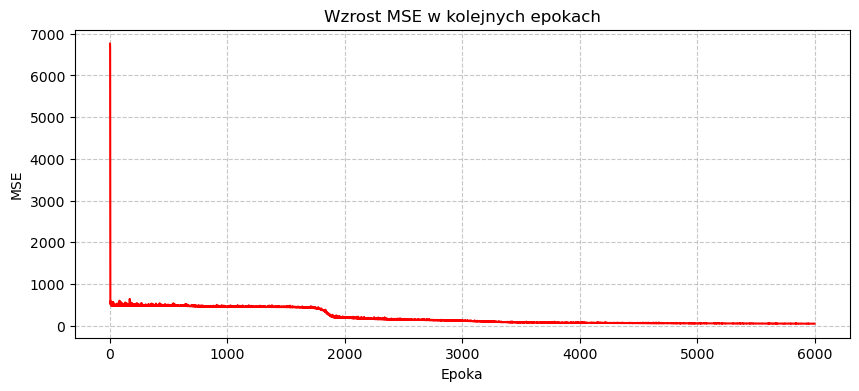

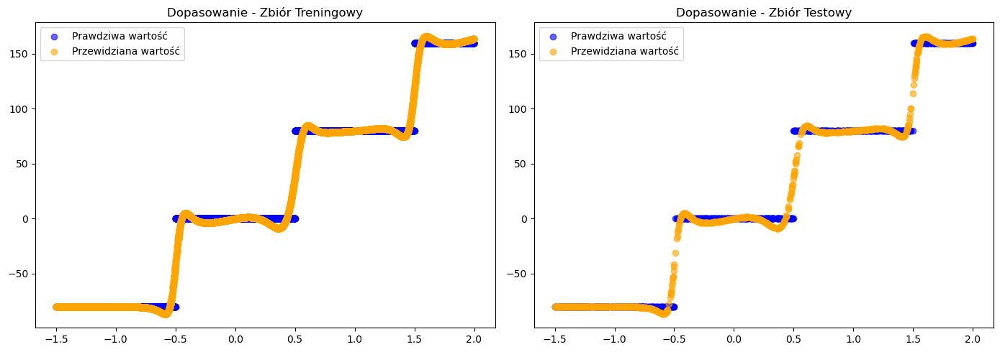

In [321]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3, sigmoid_3 = train(X_train, y_train, X_test, y_test, model, 6000, 64, funkcja_straty=MSE, regresja=True, test=True)

Krok     0 | MSE Trening: 494.3046
Krok   100 | MSE Trening: 435.8693
Krok   200 | MSE Trening: 205.4680
Krok   300 | MSE Trening:  72.2450
Krok   400 | MSE Trening:  57.2773
Krok   500 | MSE Trening:  41.5871
Krok   600 | MSE Trening:  38.7771
Krok   700 | MSE Trening:  46.0664
Krok   800 | MSE Trening:  27.6413
Krok   900 | MSE Trening:  66.4567
Krok  1000 | MSE Trening:  27.5525
Krok  1100 | MSE Trening:  33.0924
Krok  1200 | MSE Trening:  22.3770
Krok  1300 | MSE Trening:  22.5220
Krok  1400 | MSE Trening:  18.5846
Krok  1500 | MSE Trening:  18.9747
Krok  1600 | MSE Trening:  26.5807
Krok  1700 | MSE Trening:  20.4002
Krok  1800 | MSE Trening:  18.8543
Krok  1900 | MSE Trening:  16.3951
Krok  2000 | MSE Trening:  20.2081
Krok  2100 | MSE Trening:  18.5894
Krok  2200 | MSE Trening:  18.8307
Krok  2300 | MSE Trening:  15.4986
Krok  2400 | MSE Trening:  23.3843
Krok  2500 | MSE Trening:  14.0489
Krok  2600 | MSE Trening:  16.9724
Krok  2700 | MSE Trening:  13.3137
Krok  2800 | MSE Tre

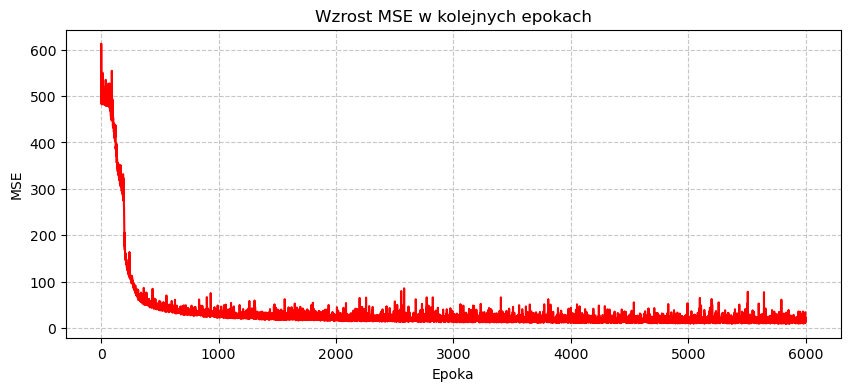

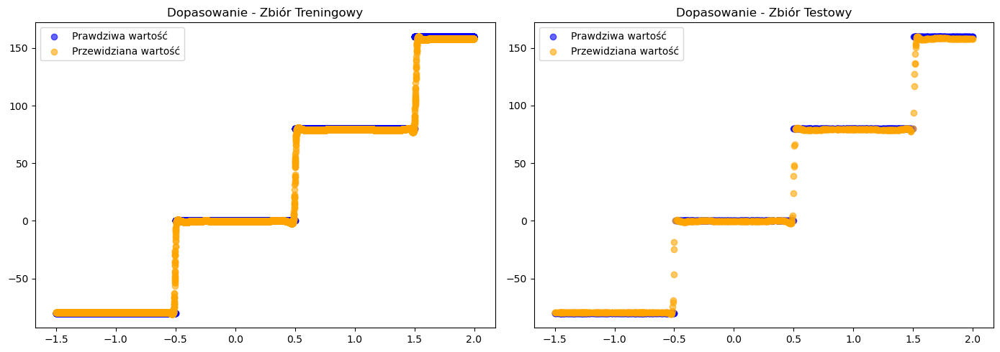

In [322]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3, tanh_3 = train(X_train, y_train, X_test, y_test, model, 6000, 64, funkcja_straty=MSE, regresja=True, test=True)

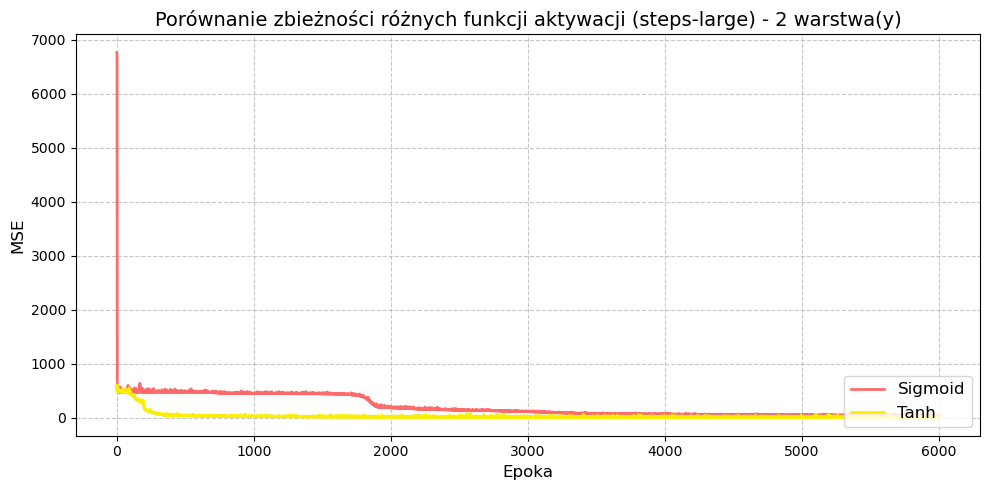

In [323]:
wykres_score('steps-large', 'MSE', hist_tanh=hist_tanh_3, hist_sigmoid=hist_sigmoid_3, warstwa=2)

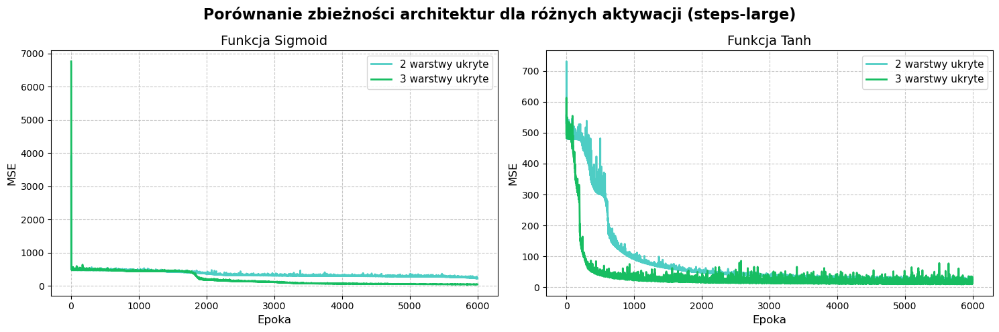

In [324]:
historie_do_wykresu = {
    'Sigmoid':    (None, hist_sigmoid_2, hist_sigmoid_3),
    'Tanh':    (None, hist_tanh_2, hist_tanh_3)
}

wykresy_warstwy(historie_do_wykresu, zbior="steps-large", score="MSE")

# Dane rings5-regular

In [261]:
rings5_regular_test = pd.read_csv("mio1/classification/rings5-regular-test.csv")
rings5_regular_train = pd.read_csv("mio1/classification/rings5-regular-training.csv")

X_train = rings5_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings5_regular_train[['c']].to_numpy().astype(int) 
X_test = rings5_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings5_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

## Dwie warstwy ukryte

Krok     0 | F1 Trening:   0.0667
Krok   100 | F1 Trening:   0.5976
Krok   200 | F1 Trening:   0.7780
Krok   300 | F1 Trening:   0.8559
Krok   400 | F1 Trening:   0.8918
Krok   500 | F1 Trening:   0.9074
Krok   600 | F1 Trening:   0.9144
Krok   700 | F1 Trening:   0.9117
Krok   800 | F1 Trening:   0.9091
Krok   900 | F1 Trening:   0.9317
Krok  1000 | F1 Trening:   0.9222
Krok  1100 | F1 Trening:   0.9266
Krok  1200 | F1 Trening:   0.9144
Krok  1300 | F1 Trening:   0.9084
Krok  1400 | F1 Trening:   0.9292
Krok  1500 | F1 Trening:   0.9258
Krok  1600 | F1 Trening:   0.9372
Krok  1700 | F1 Trening:   0.9282
Krok  1800 | F1 Trening:   0.9308
Krok  1900 | F1 Trening:   0.9360
--------------------------------------------------
F1 treningowe FINALNE: 0.9475
F1 testowe FINALNE: 0.8968


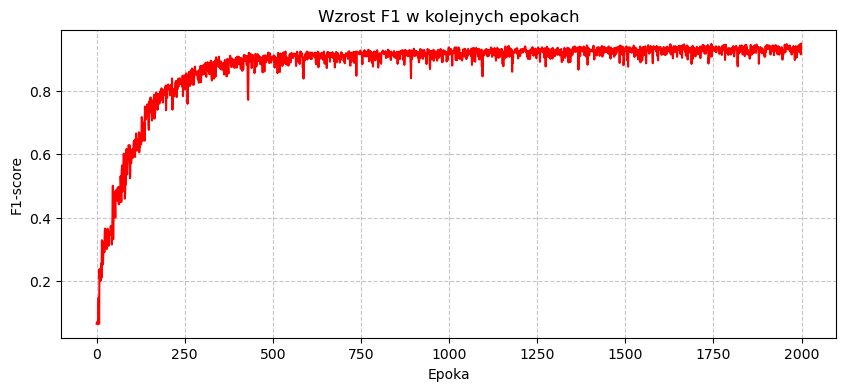

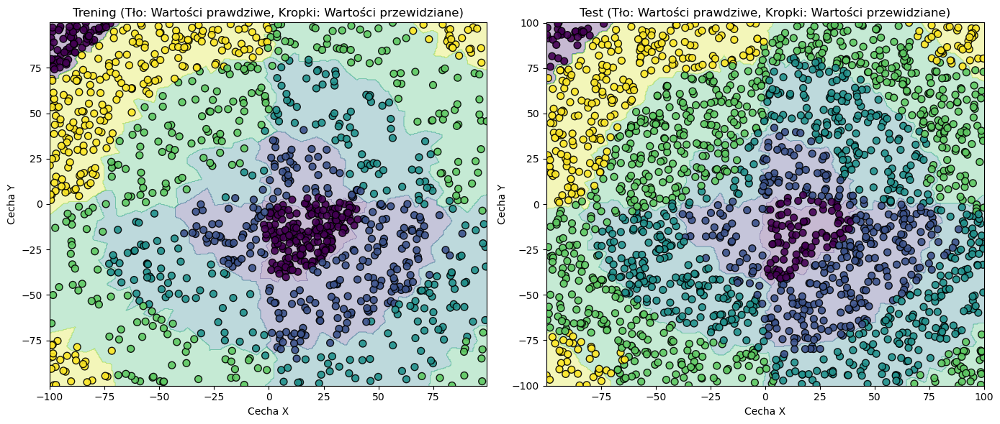

In [262]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2, sigmoid_2 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

Krok     0 | F1 Trening:   0.2632
Krok   100 | F1 Trening:   0.8150
Krok   200 | F1 Trening:   0.8248
Krok   300 | F1 Trening:   0.8274
Krok   400 | F1 Trening:   0.7642
Krok   500 | F1 Trening:   0.8185
Krok   600 | F1 Trening:   0.8440
Krok   700 | F1 Trening:   0.8442
Krok   800 | F1 Trening:   0.8189
Krok   900 | F1 Trening:   0.8565
Krok  1000 | F1 Trening:   0.8548
Krok  1100 | F1 Trening:   0.8049
Krok  1200 | F1 Trening:   0.8226
Krok  1300 | F1 Trening:   0.8612
Krok  1400 | F1 Trening:   0.8644
Krok  1500 | F1 Trening:   0.8201
Krok  1600 | F1 Trening:   0.7236
Krok  1700 | F1 Trening:   0.8535
Krok  1800 | F1 Trening:   0.8384
Krok  1900 | F1 Trening:   0.8557
--------------------------------------------------
F1 treningowe FINALNE: 0.8434
F1 testowe FINALNE: 0.7789


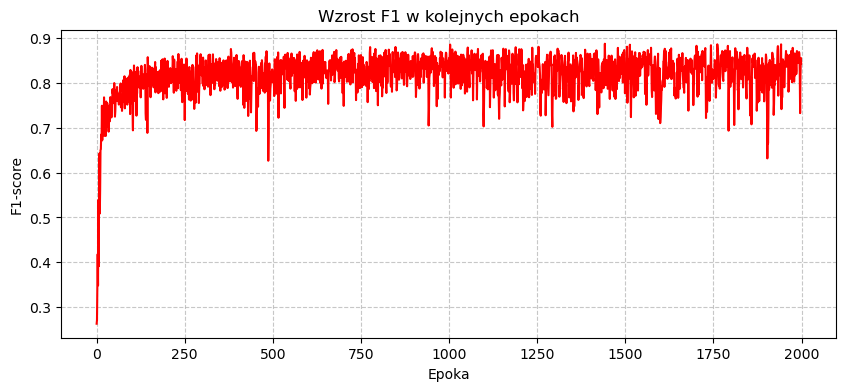

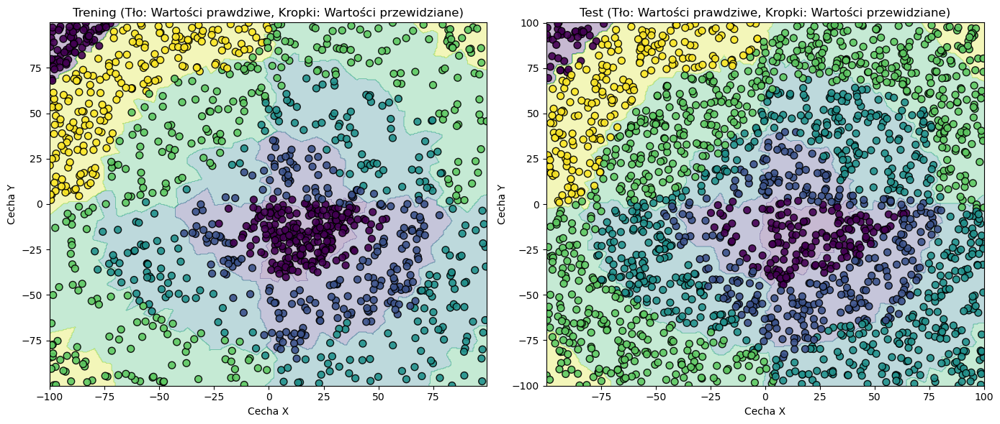

In [263]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2, tanh_2 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

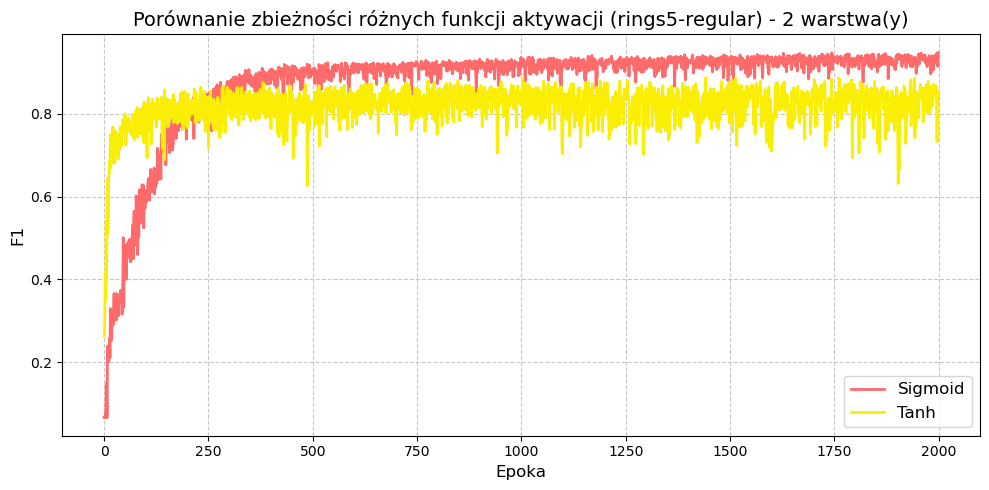

In [264]:
wykres_score('rings5-regular', 'F1', hist_sigmoid=hist_sigmoid_2, hist_tanh=hist_tanh_2, warstwa=2)

## Trzy warstwy ukryte

Krok     0 | F1 Trening:   0.0667
Krok   100 | F1 Trening:   0.4369
Krok   200 | F1 Trening:   0.5849
Krok   300 | F1 Trening:   0.8688
Krok   400 | F1 Trening:   0.8938
Krok   500 | F1 Trening:   0.8856
Krok   600 | F1 Trening:   0.9092
Krok   700 | F1 Trening:   0.9353
Krok   800 | F1 Trening:   0.9313
Krok   900 | F1 Trening:   0.9406
Krok  1000 | F1 Trening:   0.9510
Krok  1100 | F1 Trening:   0.9728
Krok  1200 | F1 Trening:   0.9671
Krok  1300 | F1 Trening:   0.9614
Krok  1400 | F1 Trening:   0.9586
Krok  1500 | F1 Trening:   0.9687
Krok  1600 | F1 Trening:   0.9712
Krok  1700 | F1 Trening:   0.9607
Krok  1800 | F1 Trening:   0.9414
Krok  1900 | F1 Trening:   0.9768
--------------------------------------------------
F1 treningowe FINALNE: 0.9824
F1 testowe FINALNE: 0.9393


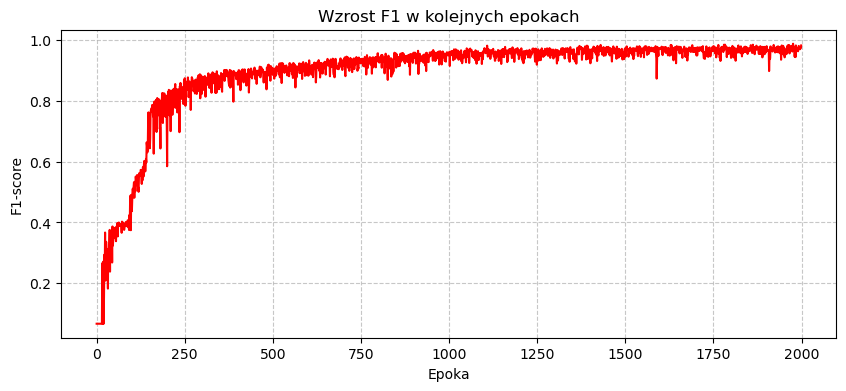

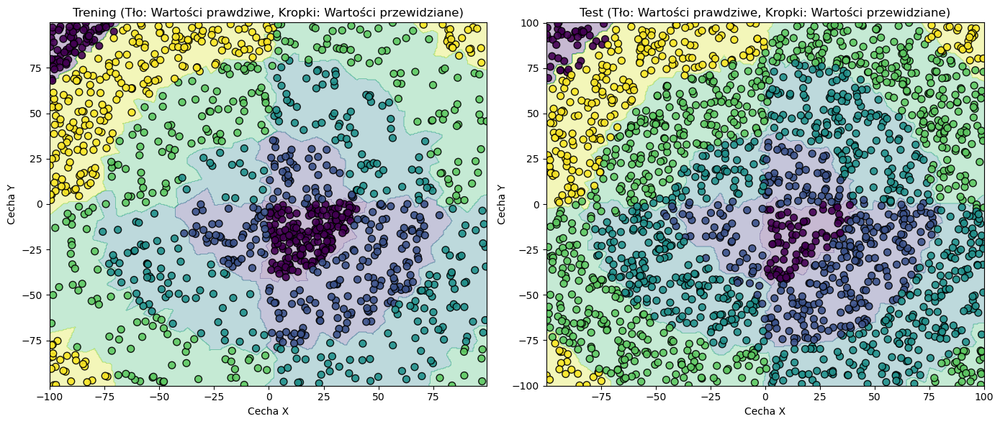

In [265]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3, sigmoid_3 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

Krok     0 | F1 Trening:   0.3013
Krok   100 | F1 Trening:   0.8010
Krok   200 | F1 Trening:   0.8660
Krok   300 | F1 Trening:   0.9140
Krok   400 | F1 Trening:   0.8810
Krok   500 | F1 Trening:   0.9138
Krok   600 | F1 Trening:   0.9178
Krok   700 | F1 Trening:   0.9095
Krok   800 | F1 Trening:   0.9446
Krok   900 | F1 Trening:   0.9396
Krok  1000 | F1 Trening:   0.9165
Krok  1100 | F1 Trening:   0.9344
Krok  1200 | F1 Trening:   0.9314
Krok  1300 | F1 Trening:   0.9311
Krok  1400 | F1 Trening:   0.9375
Krok  1500 | F1 Trening:   0.9118
Krok  1600 | F1 Trening:   0.9615
Krok  1700 | F1 Trening:   0.9639
Krok  1800 | F1 Trening:   0.8824
Krok  1900 | F1 Trening:   0.8939
--------------------------------------------------
F1 treningowe FINALNE: 0.8955
F1 testowe FINALNE: 0.8426


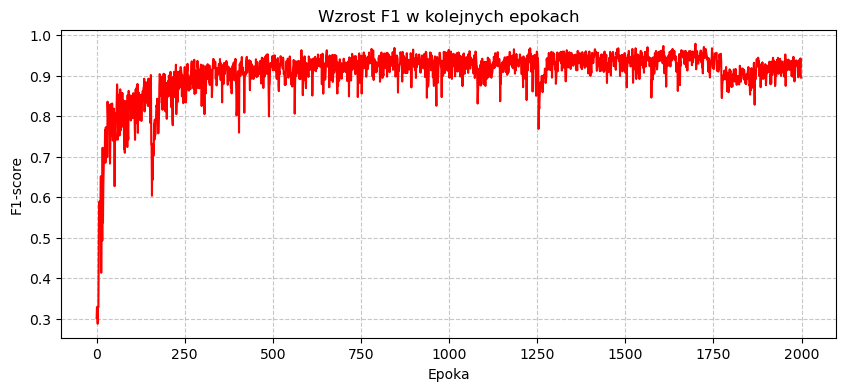

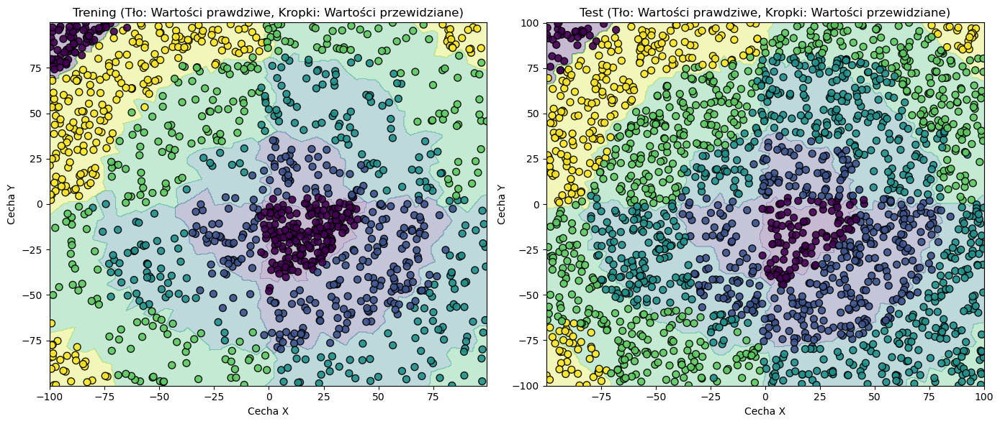

In [266]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3, tanh_3 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

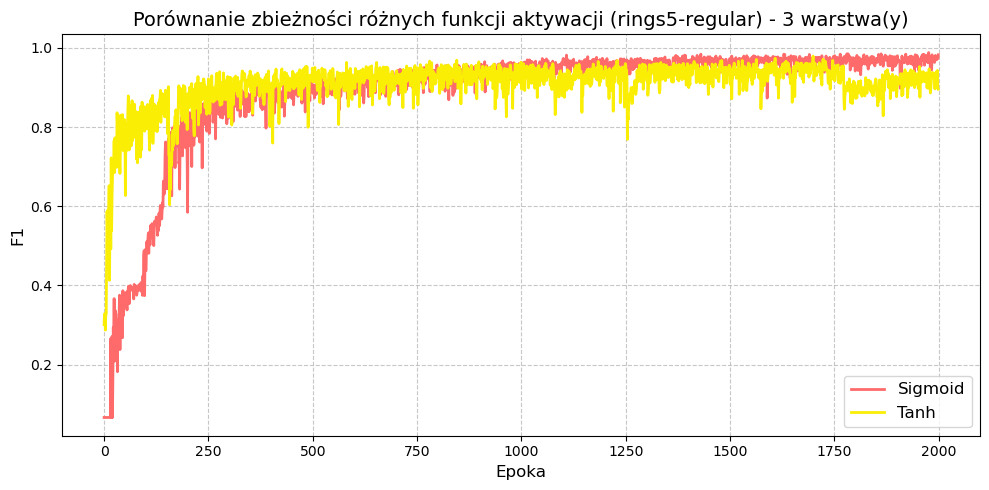

In [267]:
wykres_score('rings5-regular', 'F1', hist_sigmoid=hist_sigmoid_3, hist_tanh=hist_tanh_3, warstwa=3)

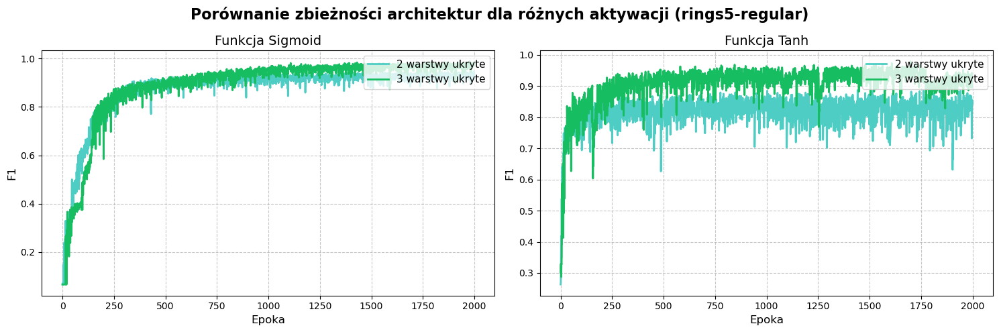

In [268]:
historie_do_wykresu = {
    'Sigmoid': (None, hist_sigmoid_2, hist_sigmoid_3),
    'Tanh':    (None, hist_tanh_2, hist_tanh_3)
}

wykresy_warstwy(historie_do_wykresu, zbior="rings5-regular", score="F1")

# Dane rings3-regular

In [269]:
rings3_regular_test = pd.read_csv("mio1/classification/rings3-regular-test.csv")
rings3_regular_train = pd.read_csv("mio1/classification/rings3-regular-training.csv")

X_train = rings3_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_regular_train[['c']].to_numpy().astype(int) 
X_test = rings3_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

Krok     0 | F1 Trening:   0.1667
Krok   100 | F1 Trening:   0.5475
Krok   200 | F1 Trening:   0.8696
Krok   300 | F1 Trening:   0.8987
Krok   400 | F1 Trening:   0.9347
Krok   500 | F1 Trening:   0.9412
Krok   600 | F1 Trening:   0.9700
Krok   700 | F1 Trening:   0.9425
Krok   800 | F1 Trening:   0.9726
Krok   900 | F1 Trening:   0.9401
Krok  1000 | F1 Trening:   0.9647
Krok  1100 | F1 Trening:   0.9533
Krok  1200 | F1 Trening:   0.9654
Krok  1300 | F1 Trening:   0.9072
Krok  1400 | F1 Trening:   0.9664
Krok  1500 | F1 Trening:   0.9617
Krok  1600 | F1 Trening:   0.9466
Krok  1700 | F1 Trening:   0.9639
Krok  1800 | F1 Trening:   0.9641
Krok  1900 | F1 Trening:   0.9705
--------------------------------------------------
F1 treningowe FINALNE: 0.9593
F1 testowe FINALNE: 0.9408


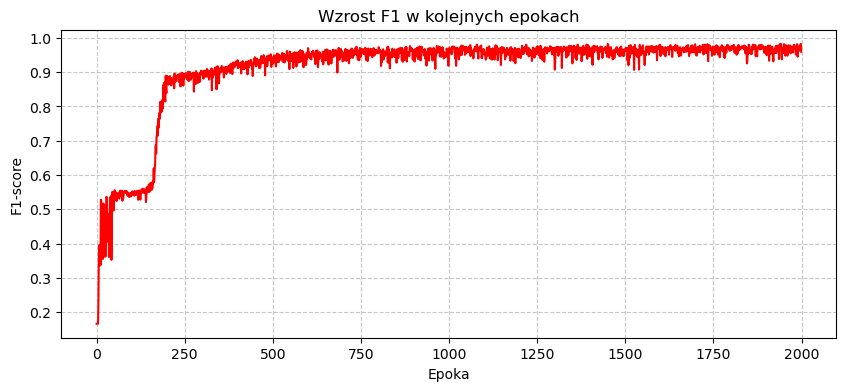

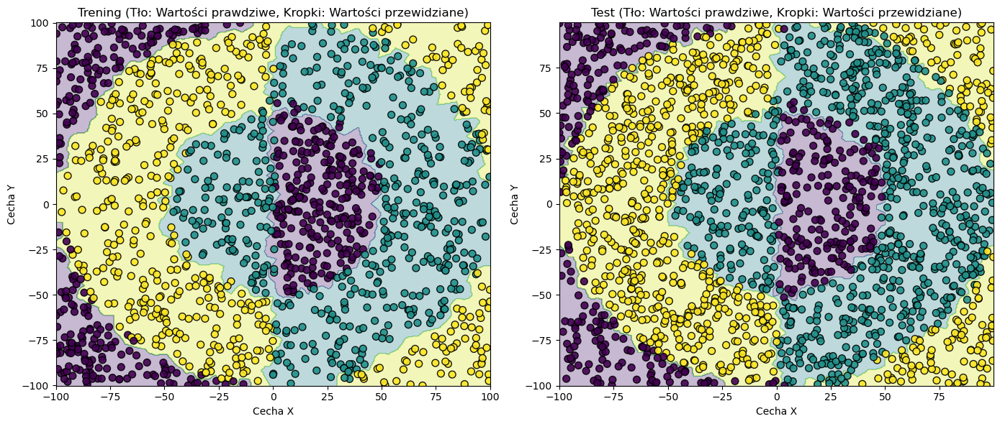

In [270]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_2, sigmoid_2 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

Krok     0 | F1 Trening:   0.4698
Krok   100 | F1 Trening:   0.9343
Krok   200 | F1 Trening:   0.9405
Krok   300 | F1 Trening:   0.9394
Krok   400 | F1 Trening:   0.9428
Krok   500 | F1 Trening:   0.9004
Krok   600 | F1 Trening:   0.9225
Krok   700 | F1 Trening:   0.9235
Krok   800 | F1 Trening:   0.9566
Krok   900 | F1 Trening:   0.9464
Krok  1000 | F1 Trening:   0.9538
Krok  1100 | F1 Trening:   0.9207
Krok  1200 | F1 Trening:   0.9262
Krok  1300 | F1 Trening:   0.9565
Krok  1400 | F1 Trening:   0.9260
Krok  1500 | F1 Trening:   0.9547
Krok  1600 | F1 Trening:   0.9567
Krok  1700 | F1 Trening:   0.9459
Krok  1800 | F1 Trening:   0.9376
Krok  1900 | F1 Trening:   0.9255
--------------------------------------------------
F1 treningowe FINALNE: 0.9498
F1 testowe FINALNE: 0.9196


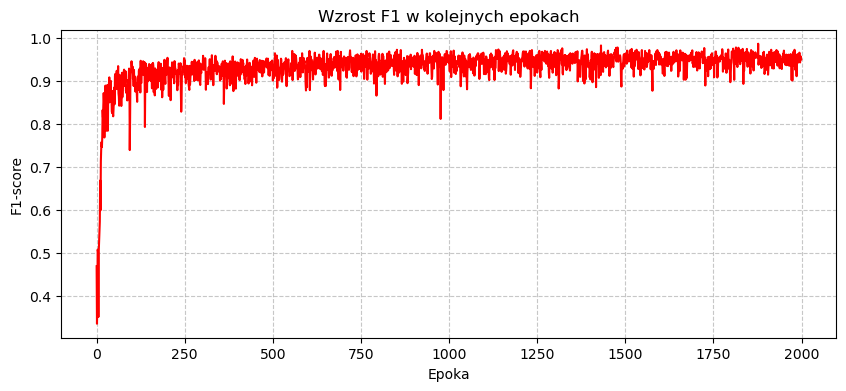

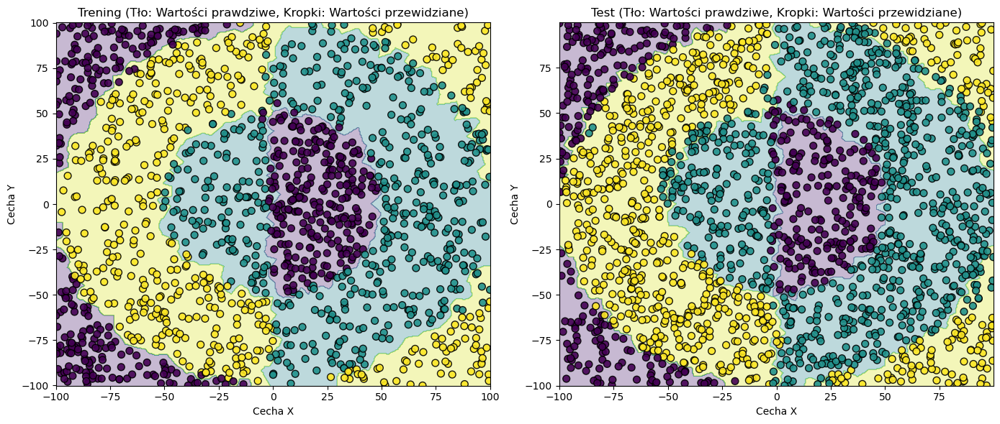

In [271]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_2, tanh_2 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

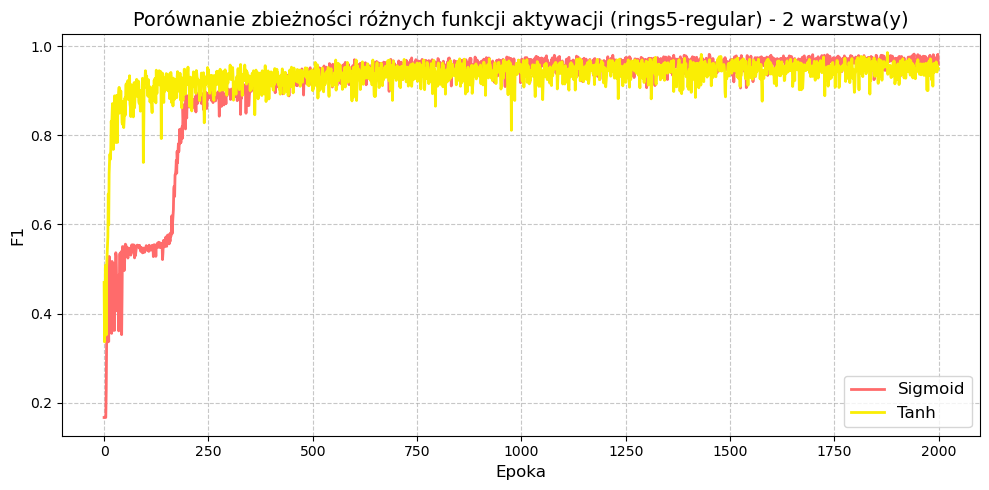

In [272]:
wykres_score('rings5-regular', 'F1', hist_sigmoid=hist_sigmoid_2, hist_tanh=hist_tanh_2, warstwa=2)

Krok     0 | F1 Trening:   0.1667
Krok   100 | F1 Trening:   0.5549
Krok   200 | F1 Trening:   0.6900
Krok   300 | F1 Trening:   0.8986
Krok   400 | F1 Trening:   0.9397
Krok   500 | F1 Trening:   0.9488
Krok   600 | F1 Trening:   0.9693
Krok   700 | F1 Trening:   0.9706
Krok   800 | F1 Trening:   0.9760
Krok   900 | F1 Trening:   0.9526
Krok  1000 | F1 Trening:   0.9734
Krok  1100 | F1 Trening:   0.9457
Krok  1200 | F1 Trening:   0.9433
Krok  1300 | F1 Trening:   0.9780
Krok  1400 | F1 Trening:   0.9577
Krok  1500 | F1 Trening:   0.9773
Krok  1600 | F1 Trening:   0.9753
Krok  1700 | F1 Trening:   0.9687
Krok  1800 | F1 Trening:   0.9780
Krok  1900 | F1 Trening:   0.9840
--------------------------------------------------
F1 treningowe FINALNE: 0.9707
F1 testowe FINALNE: 0.9592


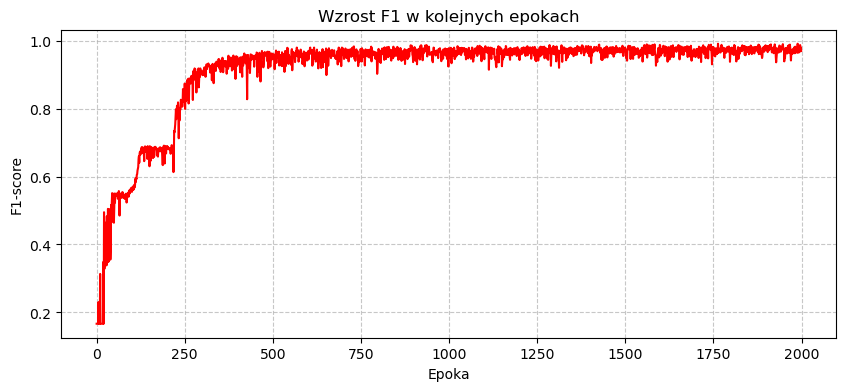

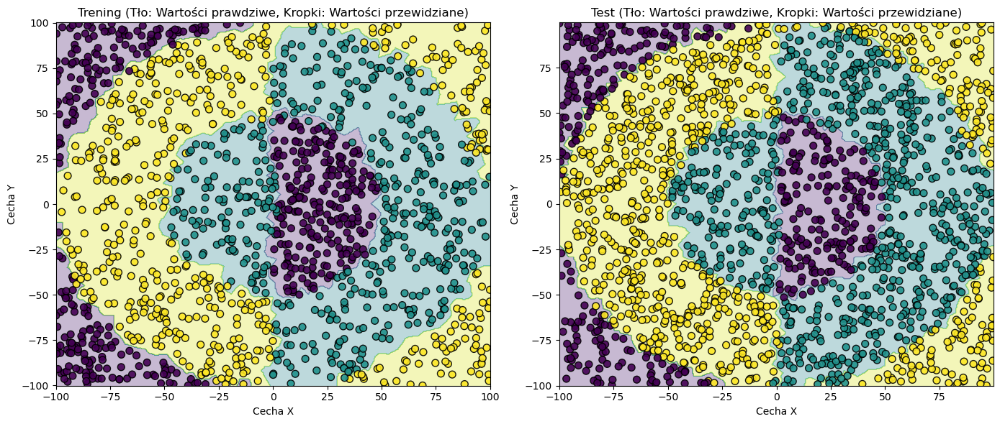

In [273]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid(), warstwa_4, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_sigmoid_3, sigmoid_3 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

Krok     0 | F1 Trening:   0.3356
Krok   100 | F1 Trening:   0.8877
Krok   200 | F1 Trening:   0.9074
Krok   300 | F1 Trening:   0.9362
Krok   400 | F1 Trening:   0.9640
Krok   500 | F1 Trening:   0.9334
Krok   600 | F1 Trening:   0.9440
Krok   700 | F1 Trening:   0.9364
Krok   800 | F1 Trening:   0.9428
Krok   900 | F1 Trening:   0.9426
Krok  1000 | F1 Trening:   0.9531
Krok  1100 | F1 Trening:   0.9439
Krok  1200 | F1 Trening:   0.8867
Krok  1300 | F1 Trening:   0.9535
Krok  1400 | F1 Trening:   0.8996
Krok  1500 | F1 Trening:   0.9645
Krok  1600 | F1 Trening:   0.9686
Krok  1700 | F1 Trening:   0.9392
Krok  1800 | F1 Trening:   0.9492
Krok  1900 | F1 Trening:   0.9410
--------------------------------------------------
F1 treningowe FINALNE: 0.9580
F1 testowe FINALNE: 0.9388


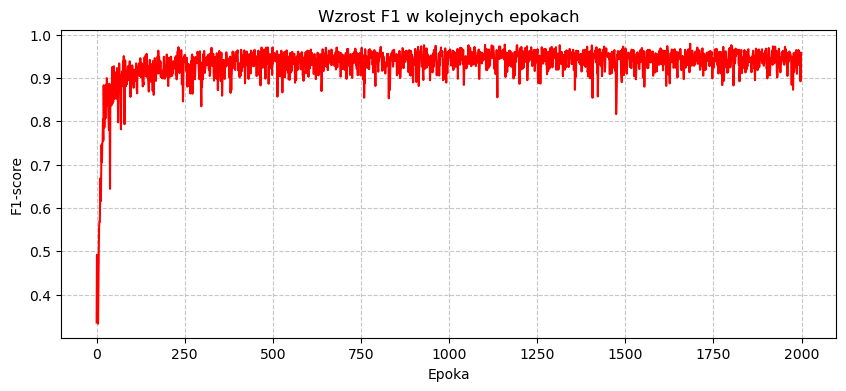

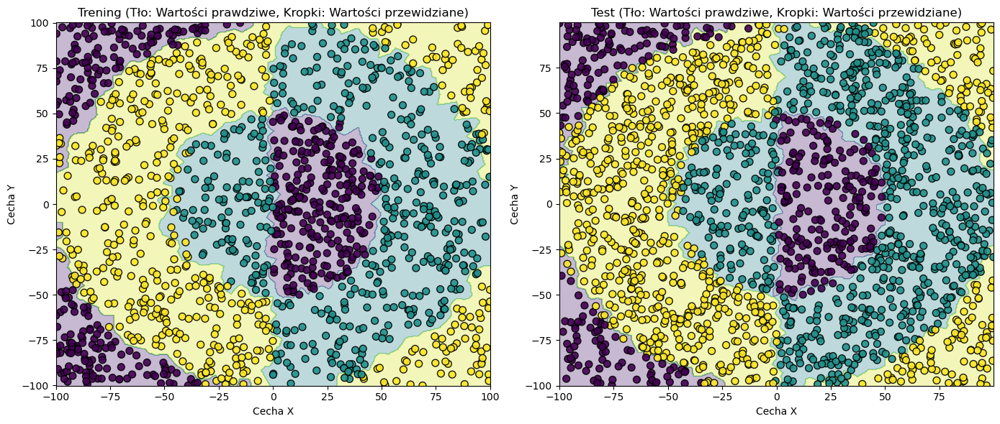

In [274]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 5, 'xavier')
warstwa_4 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, tanh(), warstwa_4, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
hist_tanh_3, tanh_3 = train(X_train, y_train, X_test, y_test, model, 2000, 64, funkcja_straty=Crossentropy, regresja=False, test=True)

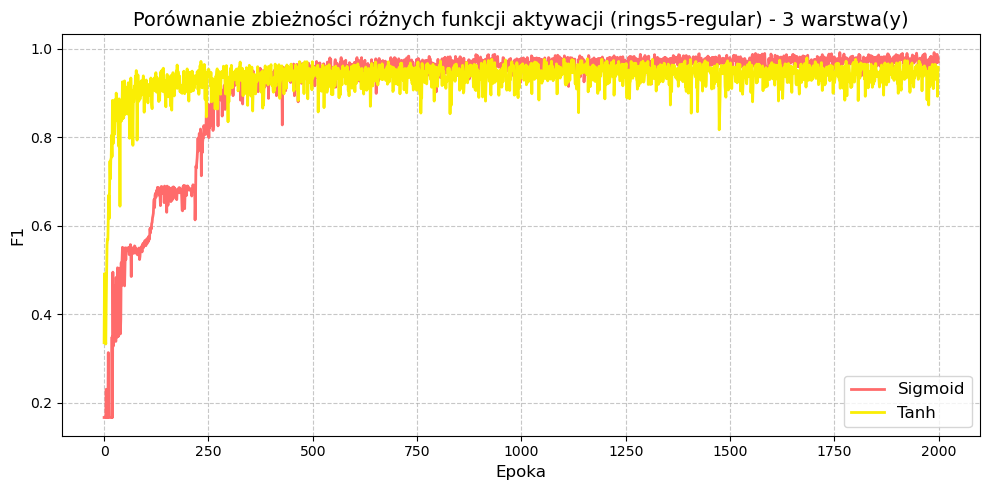

In [275]:
wykres_score('rings5-regular', 'F1', hist_sigmoid=hist_sigmoid_3, hist_tanh=hist_tanh_3, warstwa=3)

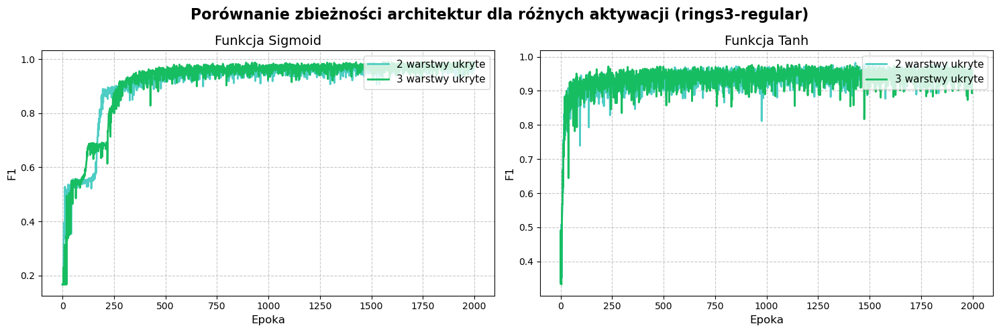

In [276]:
historie_do_wykresu = {
    'Sigmoid': (None, hist_sigmoid_2, hist_sigmoid_3),
    'Tanh':    (None, hist_tanh_2, hist_tanh_3)
}

wykresy_warstwy(historie_do_wykresu, zbior="rings3-regular", score="F1")